# Diabetes Risk Classification: Traditional Machine Learning vs Deep Learning

Machine Learning summative project, African Leadership University.
Author: *(your name)*

| Deliverable | Link |
|---|---|
| GitHub repository | https://github.com/b-sandrine/summative_introduction_to_machine_learning |
| Google Drive folder (dataset and saved models) | https://drive.google.com/drive/folders/146lM7T1nxHQci1VZSS6UHOByGKVHfQxW?usp=sharing |
| Presentation video | *(add the link after recording)* |

**What this project does.** It uses the answers of 253,680 people to a health survey (CDC BRFSS 2015) to predict whether a person has diabetes. I compare traditional machine learning (scikit-learn) with deep learning (TensorFlow/Keras), run many experiments, and look closely at the mistakes the best models make.

**How the notebook is organised.** Each step has its own numbered sections (1, 2, 3, ...) and ends with a short summary and three questions that I answer in my own words.

| Step | Content |
|---|---|
| 2 | Exploratory data analysis |
| 3 | Preprocessing and feature engineering |
| 4 | Traditional machine learning |
| 5 | Deep learning |
| 6 | Experiment tracking and comparison |
| 7 | Error analysis on the test set |

(Step 1 was the project setup: repository, folders and README.)

**About AI help.** An AI assistant (Claude) helped to write the code and the explanations in this notebook. All numbers come from running the cells. The answers to the questions at the end of each step are my own, and I declare the AI help as the university asks.

---
# Step 2: Exploratory data analysis (EDA)

Before building any model I want to know what is in the data: how big it is, whether anything is missing, how balanced the target is, and which answers seem related to diabetes.

## 1. Setup
Import the libraries, fix the random seed (so the results can be repeated) and find the dataset file. The dataset is not stored on GitHub, so the notebook looks for it in the usual places: the `dataset/` folder of the project, or a `dataset/` folder in Colab.

In [1]:
# Colab only: remove the "#" in front of the next line to install the one library that Colab does not have.
# !pip install -q imbalanced-learn

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                      # every random choice in this notebook uses this number
np.random.seed(SEED)

# The notebook lives in notebooks/, so the project folder is one level up.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMAGES_DIR = ROOT / "images"
IMAGES_DIR.mkdir(exist_ok=True)


def find_dataset_file(file_name):
    # Look for the dataset in the places where it is usually stored and stop with a clear message if it is missing.
    for folder in [ROOT / "dataset", Path("/content/dataset")]:
        if (folder / file_name).exists():
            return folder / file_name
    raise FileNotFoundError(f"{file_name} not found. Put the CSV files in the 'dataset' folder (see the README).")


DATA_FILE = find_dataset_file("diabetes_binary_health_indicators_BRFSS2015.csv")
THREE_CLASS_FILE = find_dataset_file("diabetes_012_health_indicators_BRFSS2015.csv")   # only used to check what the target means

# Two colours that are easy to tell apart, also for colour-blind readers
BLUE, ORANGE = "#0072B2", "#D55E00"


def save_and_show(figure_name):
    # Save the current figure in images/ (the report uses these files) and show it in the notebook.
    plt.savefig(IMAGES_DIR / f"{figure_name}.png", bbox_inches="tight", dpi=150)
    plt.show()


print("Using the data file:", DATA_FILE)

Using the data file: /Users/MAC/Documents/projects/ALU/summative_introduction_to_machine_learning/dataset/diabetes_binary_health_indicators_BRFSS2015.csv


## 2. Load the data and take a first look

In [2]:
diabetes_data = pd.read_csv(DATA_FILE)
print("Rows:", diabetes_data.shape[0], "| Columns:", diabetes_data.shape[1])
print("The assignment needs at least 20,000 raw rows ->", "OK" if diabetes_data.shape[0] >= 20000 else "NOT ENOUGH")
diabetes_data.head()

Rows: 253680 | Columns: 22
The assignment needs at least 20,000 raw rows -> OK


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
# Every column is stored as a decimal number, even the yes/no answers that are only 0 or 1.
diabetes_data.dtypes

Diabetes_binary         float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

### What the columns mean
All columns come from the CDC BRFSS 2015 telephone survey, so they are answers given by the people themselves. The descriptions below come from the dataset documentation and the BRFSS codebook. I still have to double-check the coding of the last few columns against the codebook before I write the report.

| Column | Meaning |
|---|---|
| Diabetes_binary | **The target.** 0 = no diabetes, 1 = diabetes |
| HighBP, HighChol | a doctor said the blood pressure or cholesterol is high (0/1) |
| CholCheck | cholesterol was checked in the last 5 years (0/1) |
| BMI | body mass index (a number) |
| Smoker | smoked at least 100 cigarettes in life (0/1) |
| Stroke, HeartDiseaseorAttack | ever told they had a stroke, or heart disease or a heart attack (0/1) |
| PhysActivity | physical activity in the last 30 days, not counting the job (0/1) |
| Fruits, Veggies | eats fruit or vegetables at least once a day (0/1) |
| HvyAlcoholConsump | heavy drinker (0/1) |
| AnyHealthcare, NoDocbcCost | has health coverage, and could not see a doctor because of the cost (0/1) |
| GenHlth | general health, 1 = excellent to 5 = poor |
| MentHlth, PhysHlth | days of poor mental or physical health in the last 30 days (0 to 30) |
| DiffWalk | serious difficulty walking or climbing stairs (0/1) |
| Sex | 0 = female, 1 = male |
| Age | age group in steps of 5 years, 1 = 18-24 to 13 = 80 or older |
| Education | 1 = never attended school to 6 = college graduate |
| Income | 1 = less than $10,000 to 8 = $75,000 or more |

## 3. Data quality checks
I look for missing values, duplicate rows and impossible values.

In [4]:
print("Missing values in total:", diabetes_data.isna().sum().sum())
print("Duplicate rows:", diabetes_data.duplicated().sum(), f"({diabetes_data.duplicated().mean():.1%} of the data)")

# Which columns contain only 0 and 1 (yes/no answers) and which contain other numbers?
yes_no_columns = [column for column in diabetes_data.columns if set(diabetes_data[column].unique()) <= {0.0, 1.0}]
numeric_columns = [column for column in diabetes_data.columns if column not in yes_no_columns]
print("\nYes/no columns (including the target):", len(yes_no_columns))
print("Other columns:", numeric_columns)

Missing values in total: 0
Duplicate rows: 24206 (9.5% of the data)

Yes/no columns (including the target): 15
Other columns: ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [5]:
# Summary statistics of the non-yes/no columns. I look at the minimum and maximum to spot impossible values.
diabetes_data[numeric_columns].describe().round(2)

,BMI,GenHlth,MentHlth,PhysHlth,Age,Education,Income
count,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00
mean,28.38,2.51,3.18,4.24,8.03,5.05,6.05
std,6.61,1.07,7.41,8.72,3.05,0.99,2.07
min,12.00,1.00,0.00,0.00,1.00,1.00,1.00
25%,24.00,2.00,0.00,0.00,6.00,4.00,5.00
50%,27.00,2.00,0.00,0.00,8.00,5.00,7.00
75%,31.00,3.00,2.00,3.00,10.00,6.00,8.00
max,98.00,5.00,30.00,30.00,13.00,6.00,8.00


About the duplicates: the survey has only 22 mostly yes/no answers, so two different people can easily give exactly the same answers. The duplicates are therefore not necessarily mistakes. They still matter, because an identical row could end up in both the training set and the test set. I decide what to do about them in Step 3.

## 4. The target variable

In [6]:
class_counts = diabetes_data["Diabetes_binary"].value_counts().sort_index()
class_share = diabetes_data["Diabetes_binary"].value_counts(normalize=True).sort_index()
class_summary = pd.DataFrame({"people": class_counts, "share": class_share.round(3)})
class_summary.index = ["0 = no diabetes", "1 = diabetes"]
print(class_summary)
print("\nA model that always answers 'no diabetes' would already be right", f"{class_share[0]:.1%}", "of the time.")

                 people  share
0 = no diabetes  218334  0.861
1 = diabetes      35346  0.139

A model that always answers 'no diabetes' would already be right 86.1% of the time.


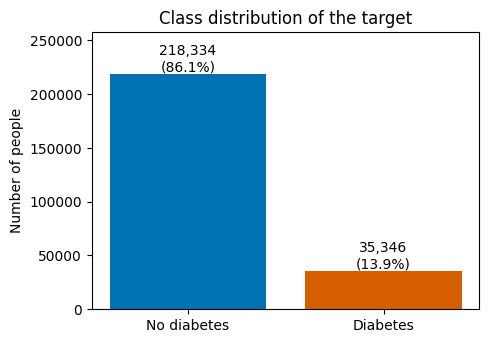

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.bar(["No diabetes", "Diabetes"], class_counts.values, color=[BLUE, ORANGE])
for position, count in enumerate(class_counts.values):
    ax.text(position, count, f"{count:,}\n({class_share.values[position]:.1%})", ha="center", va="bottom")
ax.set_ylabel("Number of people")
ax.set_title("Class distribution of the target")
ax.set_ylim(0, class_counts.max() * 1.18)
save_and_show("eda01_class_distribution")

In [8]:
# What does "diabetes = 1" really mean? The 3-class file separates 0 = no diabetes, 1 = prediabetes, 2 = diabetes,
# so I can check which of those groups the binary label contains.
three_class_data = pd.read_csv(THREE_CLASS_FILE)
print("Same number of rows in both files:", len(three_class_data) == len(diabetes_data))
print("3-class counts:", three_class_data["Diabetes_012"].value_counts().sort_index().to_dict())
binary_is_class_2 = diabetes_data["Diabetes_binary"].values == (three_class_data["Diabetes_012"].values == 2)
print("Binary target equals 'class 2 of the 3-class file' for every row:", bool(binary_is_class_2.all()))

Same number of rows in both files: True
3-class counts: {0.0: 213703, 1.0: 4631, 2.0: 35346}
Binary target equals 'class 2 of the 3-class file' for every row: True


The check shows what the binary label contains. It is 1 only for the people marked as diabetes in the 3-class file, so people with prediabetes are counted as "no diabetes" here. The UCI page describes the label as "prediabetes or diabetes", which does not match the data. I will mention this in the limitations of the report.

The classes are imbalanced: about 14 out of every 100 people have diabetes. Accuracy will look high even for a useless model, so I will also use precision, recall, F1 and ROC-AUC, and I will try class weights.

## 5. Distributions of the numeric features

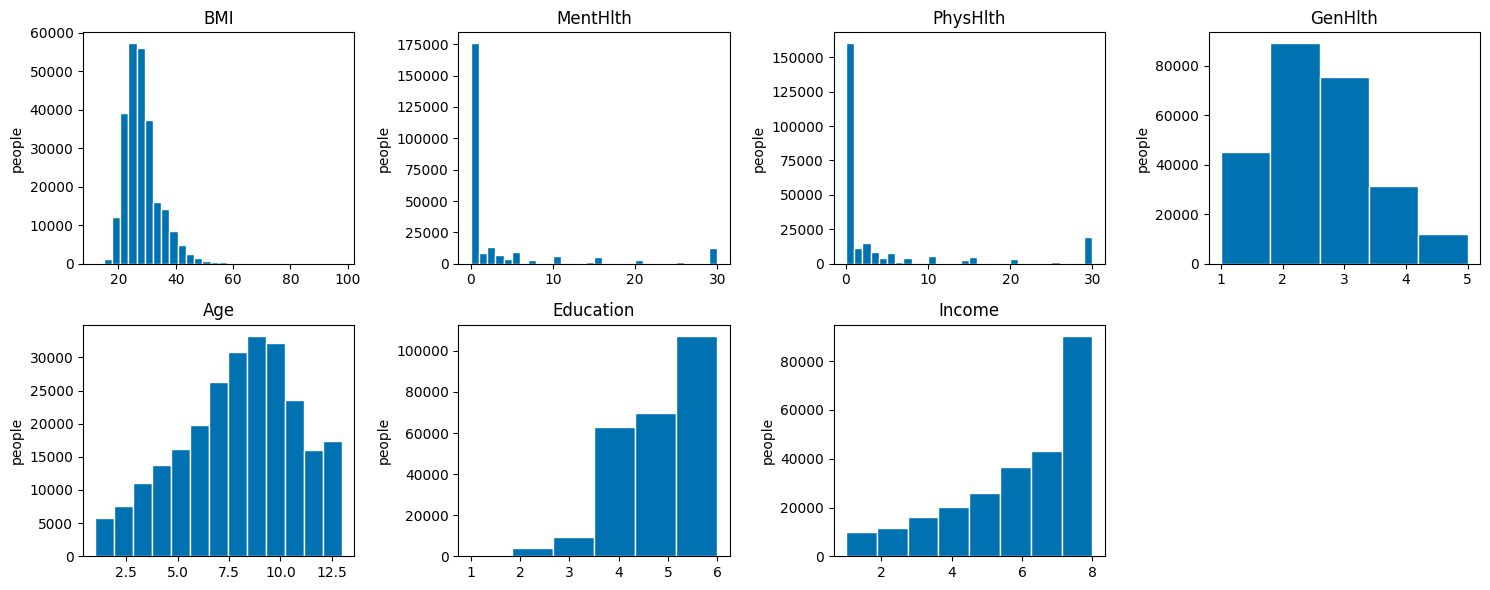

In [9]:
columns_to_plot = ["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Education", "Income"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, column in zip(axes.ravel(), columns_to_plot):
    ax.hist(diabetes_data[column], bins=min(30, diabetes_data[column].nunique()), color=BLUE, edgecolor="white")
    ax.set_title(column)
    ax.set_ylabel("people")
axes.ravel()[-1].axis("off")      # 7 plots on a grid of 8: hide the empty one
plt.tight_layout()
save_and_show("eda02_numeric_distributions")

### Outliers in BMI
BMI is the only column that is really continuous, so it is where outliers are most likely. I use the usual IQR rule: a value is an outlier if it is more than 1.5 times the IQR (the distance between the first and third quartile) outside the quartiles.

In [10]:
first_quartile, third_quartile = diabetes_data["BMI"].quantile([0.25, 0.75])
iqr = third_quartile - first_quartile
lower_limit, upper_limit = first_quartile - 1.5 * iqr, third_quartile + 1.5 * iqr
is_outlier = (diabetes_data["BMI"] < lower_limit) | (diabetes_data["BMI"] > upper_limit)

print(f"BMI range: {diabetes_data['BMI'].min():.0f} to {diabetes_data['BMI'].max():.0f} | median {diabetes_data['BMI'].median():.0f}")
print(f"IQR rule limits: {lower_limit:.1f} to {upper_limit:.1f}")
print(f"BMI outliers: {is_outlier.sum():,} rows ({is_outlier.mean():.1%})")
print("Diabetes rate among BMI outliers:", f"{diabetes_data.loc[is_outlier, 'Diabetes_binary'].mean():.1%}",
      "| among the others:", f"{diabetes_data.loc[~is_outlier, 'Diabetes_binary'].mean():.1%}")
print("BMI above 60:", (diabetes_data["BMI"] > 60).sum(), "| BMI below 15:", (diabetes_data["BMI"] < 15).sum())

BMI range: 12 to 98 | median 27
IQR rule limits: 13.5 to 41.5
BMI outliers: 9,847 rows (3.9%)
Diabetes rate among BMI outliers: 34.2% | among the others: 13.1%
BMI above 60: 805 | BMI below 15: 68


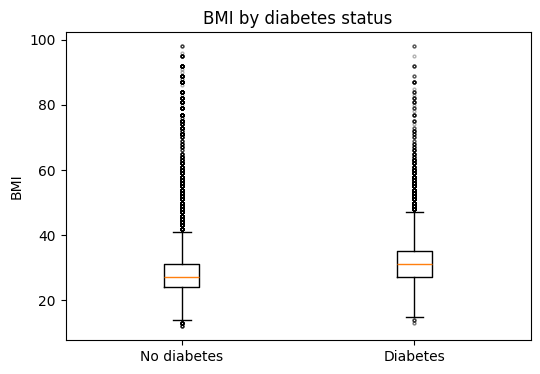

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
bmi_without_diabetes = diabetes_data.loc[diabetes_data["Diabetes_binary"] == 0, "BMI"]
bmi_with_diabetes = diabetes_data.loc[diabetes_data["Diabetes_binary"] == 1, "BMI"]
ax.boxplot([bmi_without_diabetes, bmi_with_diabetes], tick_labels=["No diabetes", "Diabetes"],
           flierprops={"markersize": 2, "alpha": 0.3})
ax.set_ylabel("BMI")
ax.set_title("BMI by diabetes status")
save_and_show("eda03_bmi_boxplot")

Many BMI values beyond the IQR limit are real, because very high BMI values exist, so they are not automatically mistakes. In Step 3 I decide to limit (cap) the extreme values instead of deleting those rows.

## 6. Relationship between each feature and diabetes
These plots show associations, not causes. People with high blood pressure having more diabetes does not prove that high blood pressure causes diabetes.

In [12]:
# For every yes/no question: the diabetes rate among people who answered 0 and among people who answered 1.
rate_rows = []
for column in yes_no_columns:
    if column == "Diabetes_binary":
        continue                      # the target is not a feature
    rate_if_no = diabetes_data.loc[diabetes_data[column] == 0, "Diabetes_binary"].mean()
    rate_if_yes = diabetes_data.loc[diabetes_data[column] == 1, "Diabetes_binary"].mean()
    rate_rows.append({"feature": column, "rate_if_0": rate_if_no, "rate_if_1": rate_if_yes, "difference": rate_if_yes - rate_if_no})
diabetes_rate_by_answer = pd.DataFrame(rate_rows).sort_values("difference")
diabetes_rate_by_answer.round(3)

,feature,rate_if_0,rate_if_1,difference
6,PhysActivity,0.211,0.116,-0.095
9,HvyAlcoholConsump,0.144,0.058,-0.086
8,Veggies,0.180,0.130,-0.050
7,Fruits,0.158,0.129,-0.029
13,Sex,0.130,0.152,0.022
10,AnyHealthcare,0.115,0.141,0.026
11,NoDocbcCost,0.136,0.175,0.039
3,Smoker,0.121,0.163,0.042
2,CholCheck,0.025,0.144,0.118
1,HighChol,0.080,0.220,0.140


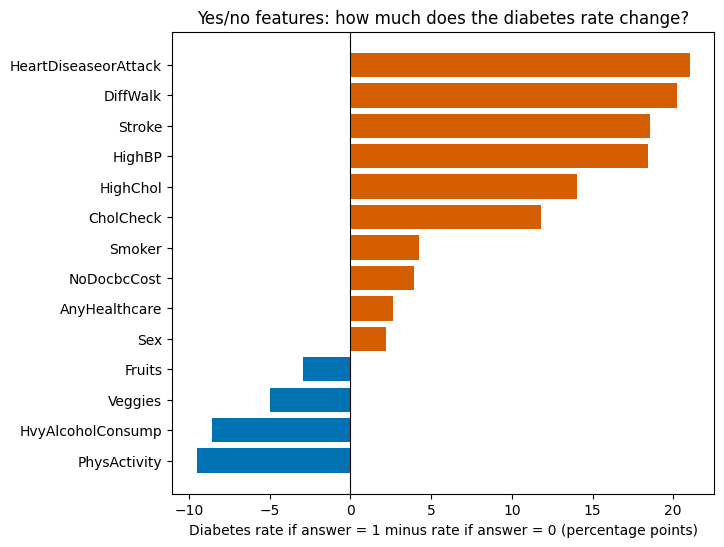

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
bar_colors = [ORANGE if difference > 0 else BLUE for difference in diabetes_rate_by_answer["difference"]]
ax.barh(diabetes_rate_by_answer["feature"], diabetes_rate_by_answer["difference"] * 100, color=bar_colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Diabetes rate if answer = 1 minus rate if answer = 0 (percentage points)")
ax.set_title("Yes/no features: how much does the diabetes rate change?")
save_and_show("eda04_binary_feature_effects")

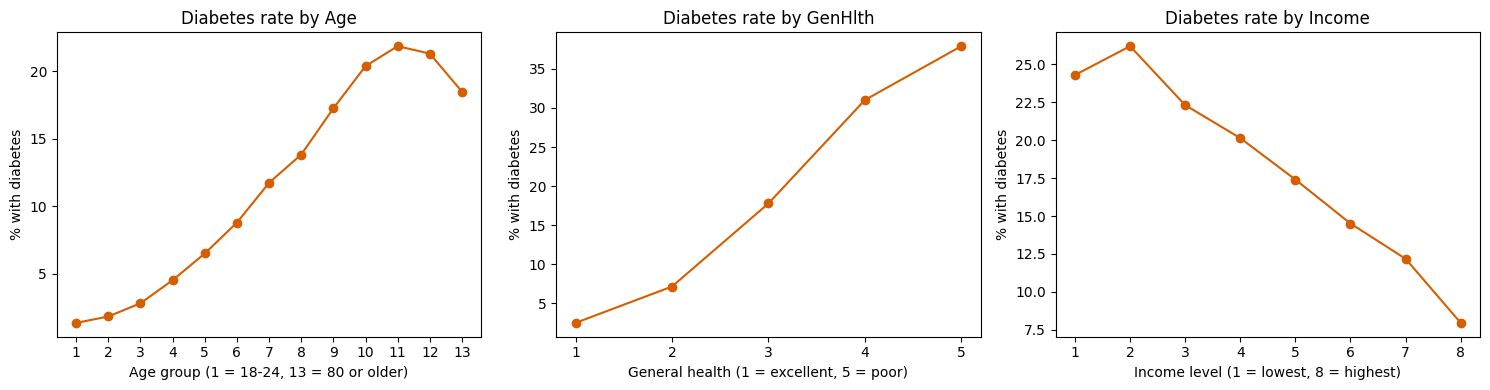

             people  diabetes_rate
BMI                               
underweight    3127          0.054
normal        68953          0.057
overweight    93749          0.114
obese         87851          0.234


In [14]:
# Diabetes rate by age group, general health and income. These are ordered scales, so a line is easier to read than bars.
# Each plot needs its own x-axis label, because "1" means something different in each column.
axis_labels = {"Age": "Age group (1 = 18-24, 13 = 80 or older)",
               "GenHlth": "General health (1 = excellent, 5 = poor)",
               "Income": "Income level (1 = lowest, 8 = highest)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["Age", "GenHlth", "Income"]):
    diabetes_percent = diabetes_data.groupby(column)["Diabetes_binary"].mean() * 100
    ax.plot(diabetes_percent.index, diabetes_percent.values, marker="o", color=ORANGE)
    ax.set_xticks(diabetes_percent.index.astype(int))          # whole numbers only: these are categories
    ax.set_xlabel(axis_labels[column])
    ax.set_ylabel("% with diabetes")
    ax.set_title(f"Diabetes rate by {column}")
plt.tight_layout()
save_and_show("eda05_rate_by_ordered_features")

# BMI groups with the WHO cut-offs (under 18.5, 18.5-25, 25-30, 30 and above)
bmi_group = pd.cut(diabetes_data["BMI"], [0, 18.5, 25, 30, 100], labels=["underweight", "normal", "overweight", "obese"], right=False)
print(diabetes_data.groupby(bmi_group, observed=True)["Diabetes_binary"].agg(people="size", diabetes_rate="mean").round(3))

## 7. Correlations
The Pearson correlation between each feature and the target. Most columns are 0/1 or ordered codes, so this is only a rough guide, and it only detects straight-line relationships.

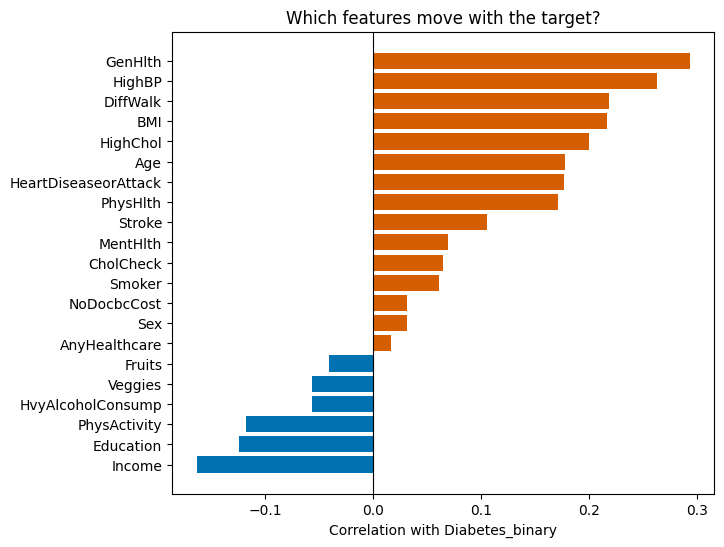

Income                 -0.164
Education              -0.124
PhysActivity           -0.118
HvyAlcoholConsump      -0.057
Veggies                -0.057
Fruits                 -0.041
AnyHealthcare           0.016
Sex                     0.031
NoDocbcCost             0.031
Smoker                  0.061
CholCheck               0.065
MentHlth                0.069
Stroke                  0.106
PhysHlth                0.171
HeartDiseaseorAttack    0.177
Age                     0.177
HighChol                0.200
BMI                     0.217
DiffWalk                0.218
HighBP                  0.263
GenHlth                 0.294


In [15]:
correlation_with_target = diabetes_data.corr()["Diabetes_binary"].drop("Diabetes_binary").sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(correlation_with_target.index, correlation_with_target.values,
        color=[ORANGE if value > 0 else BLUE for value in correlation_with_target.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlation with Diabetes_binary")
ax.set_title("Which features move with the target?")
save_and_show("eda06_target_correlation")
print(correlation_with_target.round(3).to_string())

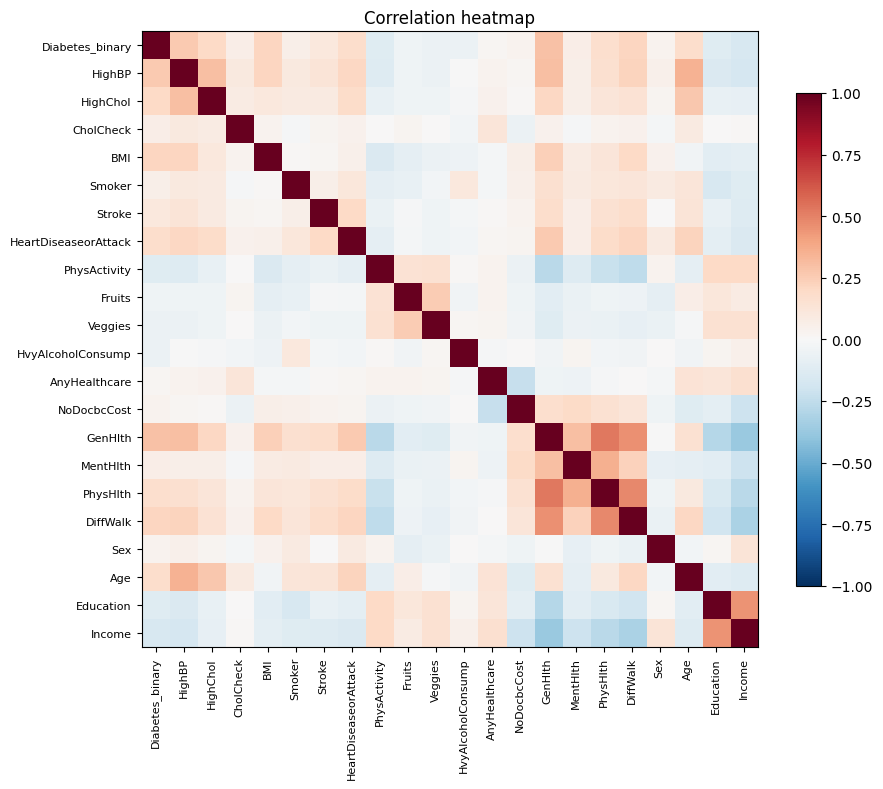

Strongest feature-to-feature correlations:
GenHlth    PhysHlth    0.524
PhysHlth   DiffWalk    0.478
GenHlth    DiffWalk    0.457
Education  Income      0.449
GenHlth    Income     -0.370


In [16]:
# Heatmap of all correlations. I look for features that carry similar information.
correlation_matrix = diabetes_data.corr()
fig, ax = plt.subplots(figsize=(10, 8))
heatmap = ax.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_matrix))); ax.set_xticklabels(correlation_matrix.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(correlation_matrix))); ax.set_yticklabels(correlation_matrix.columns, fontsize=8)
ax.grid(False)
plt.colorbar(heatmap, ax=ax, shrink=0.8)
ax.set_title("Correlation heatmap")
save_and_show("eda07_correlation_heatmap")

# The strongest correlations between two features (the target is left out).
# np.triu keeps every pair only once, because the matrix is mirrored along its diagonal.
feature_pair_correlations = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)).stack()
pairs_without_target = [pair for pair in feature_pair_correlations.index if "Diabetes_binary" not in pair]
feature_pair_correlations = feature_pair_correlations.loc[pairs_without_target]
print("Strongest feature-to-feature correlations:")
print(feature_pair_correlations.reindex(feature_pair_correlations.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

## 8. Summary of Step 2

What the output above shows:
- The raw file has 253,680 rows and 22 columns, so it meets the 20,000-row requirement. There are no missing values.
- Only about 14% of the people have diabetes, so the classes are strongly imbalanced.
- The binary target does not include prediabetes: those people are labelled 0.
- There are 24,206 exact duplicate rows. With only yes/no style answers this is expected, but it needs a decision before the data is split.
- BMI is the only continuous feature and it has a long tail of very high values.

Questions I answer in my own words before moving on:
1. Which features seem most related to diabetes, and does that match what I know about the disease?
2. What problems will the imbalance cause for the models, and what will I do about it?
3. Which preprocessing decisions follow from this analysis (duplicates, BMI outliers, scaling, new features)?

---
# Step 3: Preprocessing and feature engineering

The EDA left me with some things to deal with. The table lists each problem, what I decided and why.

| Problem found in Step 2 | Decision | Why |
|---|---|---|
| 24,206 exact duplicate rows | Remove them before splitting the data | An identical row in train and test would let a model "remember" the answer and make the test score look better than it is |
| No missing values | Check again with an assertion, no imputation | Nothing to fill in |
| BMI has a long tail (maximum 98) | Cap at the 1st and 99th percentile, learned from the training data only | Keeps the rows and stops a few extreme values from dominating the scaling and the neural network |
| Columns on very different scales (BMI about 28, days 0-30, codes 1-13) | `StandardScaler`, fitted on the training set only | Needed for logistic regression and the neural network. Fitting on the training set only avoids leakage |
| Yes/no columns are already 0/1 and ordered columns are already numbers | No one-hot encoding | There is nothing to encode. Age, Education, Income and GenHlth keep their order |
| Only 13.9% positives | Class weights first, SMOTE later as an experiment | Weights need no new data. SMOTE changes the training data, so I test it separately and only on the training set |
| Ideas for extra features | BMI category, lifestyle risk score, condition count, poor-health days | I test later whether they help |

## 1. Set up the helper functions
The reusable code (loading, de-duplication, new features, splitting, the preprocessing pipeline) is in `src/preprocessing.py`. This way every experiment uses exactly the same steps.

In [17]:
import sys
import joblib

sys.path.insert(0, str(ROOT / "src"))
from preprocessing import (TARGET, BINARY_COLUMNS, ORDINAL_COLUMNS, ENGINEERED_COLUMNS, load_data, remove_duplicates,
                           add_features, split_data, build_preprocessor, transform_to_frame, ToDataFrame)

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

raw_data = load_data(DATA_FILE)
print("Raw data:", raw_data.shape)

Raw data: (253680, 22)


## 2. Missing values and duplicates

In [18]:
# 1) Missing values: Step 2 found none, so here I only make sure that this is still true.
assert raw_data.isna().sum().sum() == 0, "There are missing values, an imputation step is needed"
print("Missing values: 0, nothing to fill in")

# 2) A more serious problem than duplicates: the same answers with a different label.
answer_columns = [column for column in raw_data.columns if column != TARGET]
labels_per_answer_profile = raw_data.groupby(answer_columns)[TARGET].nunique()
print("Answer profiles that appear with BOTH labels (0 and 1):", int((labels_per_answer_profile > 1).sum()))

# 3) Remove the exact duplicate rows and see what changes.
deduplicated_data, n_duplicates_removed = remove_duplicates(raw_data)
print(f"Rows removed: {n_duplicates_removed:,} | rows left: {len(deduplicated_data):,}")
print(f"Diabetes share before: {raw_data[TARGET].mean():.3%} | after: {deduplicated_data[TARGET].mean():.3%}")

Missing values: 0, nothing to fill in
Answer profiles that appear with BOTH labels (0 and 1): 1566


Rows removed: 24,206 | rows left: 229,474
Diabetes share before: 13.933% | after: 15.295%


Removing the duplicates changes the diabetes share a little (see the numbers above), so I will report the results on the cleaned data and say so in the report. Rows with the same answers but different labels are not exact duplicates, so they stay. Two people can answer the same way and still differ in diabetes status. This is label noise, and it limits how accurate any model can be. A small number of test rows will share their answers with a training row of the opposite label (I count them in section 5).

## 3. Outliers: cap the extreme BMI values
The real cap limits are learned from the training set inside the pipeline (section 7). Here I only look at what the limits would be on all the cleaned data, to understand their effect.

In [19]:
bmi_low_cap, bmi_high_cap = deduplicated_data["BMI"].quantile([0.01, 0.99])
n_values_capped = ((deduplicated_data["BMI"] < bmi_low_cap) | (deduplicated_data["BMI"] > bmi_high_cap)).sum()
print(f"1st and 99th percentile of BMI: {bmi_low_cap:.0f} and {bmi_high_cap:.0f}")
print(f"Values that would be capped: {n_values_capped:,} ({n_values_capped / len(deduplicated_data):.1%} of the rows). No row is deleted.")
print(f"Largest BMI before capping: {deduplicated_data['BMI'].max():.0f}, after capping: {bmi_high_cap:.0f}")

1st and 99th percentile of BMI: 18 and 50
Values that would be capped: 3,484 (1.5% of the rows). No row is deleted.
Largest BMI before capping: 98, after capping: 50


## 4. Feature engineering
I create four new columns (the code is in `src/preprocessing.py`).

| New feature | How it is built | Why |
|---|---|---|
| `bmi_category` | WHO groups: 0 underweight, 1 normal, 2 overweight, 3 obese | Step 2 showed that the diabetes rate jumps between BMI groups |
| `lifestyle_risk_score` | smoker + no physical activity + no daily fruit + no daily vegetables (0 to 4) | Combines several weak habit signals into one number |
| `condition_count` | high blood pressure + high cholesterol + stroke + heart disease + difficulty walking (0 to 5) | Several conditions together may matter more than each one alone |
| `poor_health_days` | MentHlth + PhysHlth (0 to 60) | One simple measure of how unwell the person feels |

A new feature is only useful if it helps the models. In Steps 4 and 6 I compare models with and without these columns. Here I only check that they show a sensible pattern.

In [20]:
data_with_features = add_features(deduplicated_data)
data_with_features[["BMI", "bmi_category", "lifestyle_risk_score", "condition_count", "poor_health_days"]].head()

,BMI,bmi_category,lifestyle_risk_score,condition_count,poor_health_days
0,40.0,3,3.0,3.0,33.0
1,25.0,2,3.0,0.0,0.0
2,28.0,2,2.0,3.0,60.0
3,27.0,2,0.0,1.0,0.0
4,24.0,1,0.0,2.0,3.0


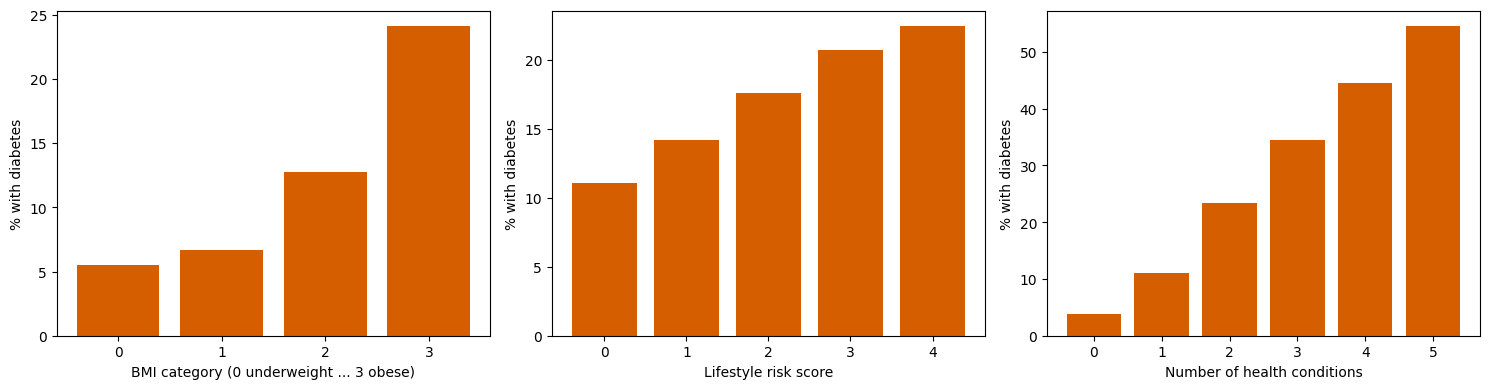

Correlation with the target (new features first, then three original ones for comparison):
bmi_category            0.194
lifestyle_risk_score    0.091
condition_count         0.327
poor_health_days        0.133
BMI                     0.205
GenHlth                 0.277
HighBP                  0.254


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, label in [(axes[0], "bmi_category", "BMI category (0 underweight ... 3 obese)"),
                          (axes[1], "lifestyle_risk_score", "Lifestyle risk score"),
                          (axes[2], "condition_count", "Number of health conditions")]:
    diabetes_percent = data_with_features.groupby(column)[TARGET].mean() * 100
    ax.bar(diabetes_percent.index.astype(int).astype(str), diabetes_percent.values, color=ORANGE)
    ax.set_xlabel(label)
    ax.set_ylabel("% with diabetes")
plt.tight_layout()
save_and_show("fe01_engineered_feature_rates")

print("Correlation with the target (new features first, then three original ones for comparison):")
print(data_with_features[ENGINEERED_COLUMNS + ["BMI", "GenHlth", "HighBP"]].corrwith(data_with_features[TARGET]).round(3).to_string())

The diabetes rate rises with `condition_count` and with `bmi_category`, which is the pattern I expected. The correlations show whether the new columns are at least as informative as the original columns they are built from. The real test is whether they improve the models, and I do that test in the experiments.

## 5. Train, validation and test split
I use 70% of the people for training, 15% for validation and 15% for testing. The split is stratified, which means that every part has the same share of people with diabetes. The seed is fixed. The validation set is used for tuning and early stopping, and the test set is only used at the very end (Step 7).

In the code, `X` is the table with the answers of the people and `y` is the column that says whether they have diabetes.

In [22]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(data_with_features)

split_sizes = pd.DataFrame({"rows": [len(X_train), len(X_val), len(X_test)],
                            "diabetes share": [y_train.mean(), y_val.mean(), y_test.mean()]},
                           index=["train", "validation", "test"])
split_sizes["diabetes share"] = split_sizes["diabetes share"].round(4)
print(split_sizes)


def complete_rows(answers, labels):
    # Every row as a tuple of the answers plus the label, so rows can be compared between the parts.
    return set(map(tuple, np.column_stack([answers.values, labels.values])))


# Leakage check 1: no complete row (answers and label) may appear in two parts.
# The duplicates were removed before the split, so the overlap must be zero.
train_complete_rows = complete_rows(X_train, y_train)
overlap_with_validation = train_complete_rows & complete_rows(X_val, y_val)
overlap_with_test = train_complete_rows & complete_rows(X_test, y_test)
print("Complete rows of the validation set found in train:", len(overlap_with_validation))
print("Complete rows of the test set found in train      :", len(overlap_with_test))
assert not overlap_with_validation and not overlap_with_test

# Check 2 (for information): test people whose answers also occur in the training set. Their labels differ,
# because the complete rows are different. This is the "same answers, different outcome" noise from section 2.
train_answers = set(map(tuple, X_train.values))
n_test_rows_with_conflicting_label = sum(tuple(row) in train_answers for row in X_test.values)
print(f"Test rows with the same answers as a training row: {n_test_rows_with_conflicting_label} "
      f"({n_test_rows_with_conflicting_label / len(X_test):.2%})")

              rows  diabetes share
train       160631          0.1529
validation   34421          0.1529
test         34422          0.1530


Complete rows of the validation set found in train: 0
Complete rows of the test set found in train      : 0


Test rows with the same answers as a training row: 326 (0.95%)


## 6. Class imbalance
Only about 15% of the cleaned data are people with diabetes. My plan:
1. Class weights (used in Steps 4 and 5). Every person with diabetes counts more in the loss, so a model cannot do well by ignoring them.
2. SMOTE (an experiment in Step 4). It creates artificial examples of the small class. It is applied to the training set only, never to the validation or test set.

In [23]:
n_without_diabetes = (y_train == 0).sum()
n_with_diabetes = (y_train == 1).sum()

# "Balanced" weights: each class gets total / (2 x its size), so both classes carry the same total weight.
class_weights = {0: len(y_train) / (2 * n_without_diabetes), 1: len(y_train) / (2 * n_with_diabetes)}
print(f"Training set: {n_without_diabetes:,} without diabetes, {n_with_diabetes:,} with diabetes "
      f"(ratio {n_without_diabetes / n_with_diabetes:.1f} to 1)")
print("Class weights (balanced):", {label: round(float(weight), 3) for label, weight in class_weights.items()})

Training set: 136,063 without diabetes, 24,568 with diabetes (ratio 5.5 to 1)
Class weights (balanced): {0: 0.59, 1: 3.269}


## 7. Build, fit and apply the preprocessing pipeline
The pipeline is fitted on the training set only. It learns the BMI limits and the means and standard deviations there. Then the same fitted pipeline transforms the validation and test sets. If I fitted it on all the data, information from the test set would leak into the training.

In [24]:
preprocessor = build_preprocessor(use_engineered=True)
preprocessor.fit(X_train)                       # learns the BMI limits, the means and the standard deviations from TRAIN only

train_scaled = transform_to_frame(preprocessor, X_train)
val_scaled = transform_to_frame(preprocessor, X_val)
test_scaled = transform_to_frame(preprocessor, X_test)

bmi_capper = preprocessor.named_transformers_["bmi"].named_steps["cap"]
print(f"BMI limits learned from the training set: {bmi_capper.low_[0]:.0f} to {bmi_capper.high_[0]:.0f}")
print("Number of features after preprocessing:", train_scaled.shape[1], "(14 yes/no + BMI + 6 ordered + 4 engineered)")

columns_to_check = ["BMI", "Age", "Income"]
scaled_means_check = pd.DataFrame({"train mean": train_scaled[columns_to_check].mean(),
                                   "train std": train_scaled[columns_to_check].std(),
                                   "val mean": val_scaled[columns_to_check].mean(),
                                   "test mean": test_scaled[columns_to_check].mean()}).round(3)
print("\nMean and standard deviation of three scaled columns:")
print(scaled_means_check)

BMI limits learned from the training set: 18 to 50
Number of features after preprocessing: 25 (14 yes/no + BMI + 6 ordered + 4 engineered)

Mean and standard deviation of three scaled columns:
        train mean  train std  val mean  test mean
BMI           -0.0        1.0     0.016      0.004
Age            0.0        1.0    -0.007      0.012
Income        -0.0        1.0    -0.004     -0.011


The training columns have a mean of 0 and a standard deviation of 1, because the scaler was fitted on them. The validation and test columns are close to 0 but not exactly 0. That is correct: they were scaled with the numbers learned from the training data.

In [25]:
# Final sanity checks before any modelling
assert not train_scaled.isna().any().any() and not val_scaled.isna().any().any() and not test_scaled.isna().any().any()
assert list(train_scaled.columns) == list(val_scaled.columns) == list(test_scaled.columns)
print("No missing values after preprocessing, and the three sets have the same columns.")
print("Shapes:", train_scaled.shape, val_scaled.shape, test_scaled.shape)

# Save the fitted pipeline, so the exact same transformation can be reused later.
joblib.dump(preprocessor, MODELS_DIR / "preprocessor.joblib")
print("Saved the preprocessing pipeline to models/preprocessor.joblib")

No missing values after preprocessing, and the three sets have the same columns.
Shapes: (160631, 25) (34421, 25) (34422, 25)
Saved the preprocessing pipeline to models/preprocessor.joblib


## 8. Summary of Step 3

What the output above shows:
- The duplicates were removed before splitting, and no complete row (answers and label) appears in more than one of the train, validation and test sets. A small share of the test rows have the same answers as a training row with the opposite label. This is label noise and it stays in the data.
- There is nothing to impute, and no categorical encoding was needed.
- The BMI outliers are capped (the limits come from the training set), not deleted.
- The pipeline is fitted on the training set only. It outputs 25 features: 14 yes/no, BMI, 6 ordered columns and 4 engineered ones.
- The share of diabetes is the same in the train, validation and test sets (stratified split, seed 42).

Questions I answer in my own words before the report:
1. Why did I remove the duplicates before the split and not after it?
2. Why is the scaler fitted on the training set only? What would go wrong if I fitted it on all the data?
3. Which of the four new features do I expect to help, and why? (The experiments in Steps 4 and 6 show if I was right.)

---
# Step 4: Traditional machine learning (scikit-learn)

The plan is to train several classic models, compare them fairly, tune the promising ones, and test two ideas: the new features and the handling of the class imbalance. Every run is recorded, so each number in the experiment table can be traced back to a real run.

| Model | Why I chose it | Expected weakness |
|---|---|---|
| Dummy (always predicts the majority class) | A baseline: every real model has to beat it | Learns nothing |
| Logistic regression | Simple, fast and easy to explain (one weight per feature) | Can only draw straight boundaries |
| Random forest | Many decision trees that vote. Handles non-linear patterns | Bigger and slower, harder to explain |
| Gradient boosting (`HistGradientBoosting`) | Trees built one after the other, each fixing the mistakes of the last. Usually strong on tables like this one | More settings to tune, can overfit if it runs too long |
| SVM (RBF kernel) | A flexible, curved boundary | Training time grows very fast with the number of rows, so I train it on a sample of 20,000 training rows (the validation set stays complete) |

Rules for a fair comparison:
- Every model is trained on the same training set and scored on the same validation set. The test set is not touched until Step 7.
- Metrics: accuracy, precision, recall, F1 (all for the diabetes class), ROC-AUC and PR-AUC. Accuracy alone is misleading, because always answering "no diabetes" is already about 85% accurate. Precision and recall use the usual cut-off of 0.5.
- I compare the models mainly with ROC-AUC, because it does not depend on the cut-off. PR-AUC and F1 matter more when the positive class is rare, so I look at them too.

How the runs are recorded (the code is in `src/tracking.py`):
1. `reports/experiment_log.csv` is the experiment table (model, settings, data split, metrics, time, observations).
2. `logs/step4_traditional_ml.log` is a plain text log.
3. `logs/tensorboard/` has one TensorBoard run per experiment, plus the curves. Start it with `tensorboard --logdir logs/tensorboard` and open http://localhost:6006. The HParams tab compares the runs and the Scalars tab shows the curves.

## 1. Setup: imports, the tracker, and one function that runs and records an experiment

In [26]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, learning_curve, train_test_split
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, log_loss, roc_auc_score
from imblearn.over_sampling import SMOTE

from tracking import ExperimentTracker, evaluate_binary

LOGS_DIR = ROOT / "logs"
REPORTS_DIR = ROOT / "reports"
experiment_tracker = ExperimentTracker(REPORTS_DIR / "experiment_log.csv", LOGS_DIR / "tensorboard",
                                       LOGS_DIR / "step4_traditional_ml.log")

# Text that is written next to every experiment in the table
SPLIT_DESCRIPTION = (f"stratified 70/15/15, seed {SEED}, duplicates removed "
                     f"(train {len(X_train):,} / val {len(X_val):,} / test {len(X_test):,})")
ALL_FEATURES_DESCRIPTION = "25 features (21 original + 4 engineered)"

# 3-fold cross-validation is used for tuning, and only on the training set.
CROSS_VALIDATION = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# For every experiment I keep the fitted model, its validation scores and the preprocessor it used.
# Later cells need them for plots and for saving the best model.
traditional_results = {}


def run_experiment(experiment_id, model_name, model, settings, train_features, train_labels,
                   eval_features, eval_labels, features_description,
                   fitted_preprocessor=preprocessor, use_decision_function=False):
    # Train the model, score it on the evaluation set, and record everything with the tracker.
    start_time = time.time()
    model.fit(train_features, train_labels)
    seconds = time.time() - start_time

    if use_decision_function:
        # The SVM here has no probabilities. Its distance to the boundary works as a score for ROC-AUC.
        scores = model.decision_function(eval_features)
        predictions = model.predict(eval_features)
    else:
        scores = model.predict_proba(eval_features)[:, 1]
        predictions = (scores >= 0.5).astype(int)
    metrics = evaluate_binary(eval_labels, scores, predictions)

    experiment_tracker.log_experiment(experiment_id, "4 traditional ML", model_name, settings, features_description,
                                      SPLIT_DESCRIPTION, f"validation ({len(eval_labels):,} rows)", metrics, seconds)
    traditional_results[experiment_id] = {"name": model_name, "model": model, "preprocessor": fitted_preprocessor,
                                          "scores": scores, "predictions": predictions, "metrics": metrics}
    return metrics


def show_traditional_results(experiment_ids):
    # A small table with the metrics of some experiments.
    rows = [{"experiment": experiment_id, "model": traditional_results[experiment_id]["name"],
             **{metric: round(value, 3) for metric, value in traditional_results[experiment_id]["metrics"].items()}}
            for experiment_id in experiment_ids]
    return pd.DataFrame(rows).set_index("experiment")

## 2. Baseline: the model that never predicts diabetes
Any useful model has to beat this one. It also shows why accuracy alone cannot be trusted here.

In [27]:
run_experiment("T01", "Dummy baseline", DummyClassifier(strategy="most_frequent"), {"strategy": "most_frequent"},
               train_scaled, y_train, val_scaled, y_val, ALL_FEATURES_DESCRIPTION)
show_traditional_results(["T01"])

18:52:07 | T01 | Dummy baseline | acc 0.847 | precision 0.000 | recall 0.000 | F1 0.000 | ROC-AUC 0.500 | PR-AUC 0.153 | 0.0s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,
T01,Dummy baseline,0.847,0.0,0.0,0.0,0.5,0.153


The baseline has a high accuracy but zero recall and zero F1 for diabetes, and its ROC-AUC is 0.5, which is no better than guessing. Accuracy would hide a useless model, so I judge the models with the other metrics as well.

## 3. First round: four models with sensible default settings
Logistic regression, random forest and gradient boosting use `class_weight="balanced"` (the idea from Step 3), so the small diabetes class counts more. The SVM is trained on a stratified sample of 20,000 training rows.

In [28]:
# T02: logistic regression with the default regularisation strength
run_experiment("T02", "Logistic regression", LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=SEED),
               {"C": 1.0, "class_weight": "balanced"}, train_scaled, y_train, val_scaled, y_val, ALL_FEATURES_DESCRIPTION)

# T03: random forest with 200 trees and no limit on the depth of the trees
run_experiment("T03", "Random forest", RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
               {"n_estimators": 200, "max_depth": "None", "class_weight": "balanced_subsample"},
               train_scaled, y_train, val_scaled, y_val, ALL_FEATURES_DESCRIPTION)

# T04: gradient boosting with the default settings
run_experiment("T04", "Gradient boosting", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
               {"learning_rate": 0.1, "max_leaf_nodes": 31, "class_weight": "balanced"},
               train_scaled, y_train, val_scaled, y_val, ALL_FEATURES_DESCRIPTION)

# T05: SVM on a sample of 20,000 training rows (the full training set would take far too long)
svm_train_features, _, svm_train_labels, _ = train_test_split(train_scaled, y_train, train_size=20000,
                                                              stratify=y_train, random_state=SEED)
run_experiment("T05", "SVM (RBF)", SVC(kernel="rbf", C=1.0, class_weight="balanced"),
               {"C": 1.0, "kernel": "rbf", "class_weight": "balanced", "train_rows": 20000},
               svm_train_features, svm_train_labels, val_scaled, y_val,
               ALL_FEATURES_DESCRIPTION + ", trained on a 20,000-row sample", use_decision_function=True)

show_traditional_results(["T01", "T02", "T03", "T04", "T05"])

18:52:07 | T02 | Logistic regression | acc 0.719 | precision 0.323 | recall 0.766 | F1 0.455 | ROC-AUC 0.815 | PR-AUC 0.430 | 0.4s


18:52:17 | T03 | Random forest | acc 0.843 | precision 0.461 | recall 0.156 | F1 0.233 | ROC-AUC 0.779 | PR-AUC 0.358 | 9.2s


18:52:19 | T04 | Gradient boosting | acc 0.710 | precision 0.320 | recall 0.796 | F1 0.457 | ROC-AUC 0.820 | PR-AUC 0.445 | 2.2s


18:53:17 | T05 | SVM (RBF) | acc 0.712 | precision 0.317 | recall 0.766 | F1 0.449 | ROC-AUC 0.799 | PR-AUC 0.371 | 10.1s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,
T01,Dummy baseline,0.847,0.000,0.000,0.000,0.500,0.153
T02,Logistic regression,0.719,0.323,0.766,0.455,0.815,0.430
T03,Random forest,0.843,0.461,0.156,0.233,0.779,0.358
T04,Gradient boosting,0.710,0.320,0.796,0.457,0.820,0.445
T05,SVM (RBF),0.712,0.317,0.766,0.449,0.799,0.371


## 4. How do the models change as they grow?
Two curves, which are also written to TensorBoard (Scalars tab, runs that start with `curve_`):
- Gradient boosting: the loss on the training and validation data after each boosting round. If the training loss keeps falling while the validation loss starts to rise, the model is overfitting.
- Random forest: the validation ROC-AUC as more trees are added.

18:53:24 | curve logged to TensorBoard run 'curve_gradient_boosting': train_loss, val_loss, val_roc_auc


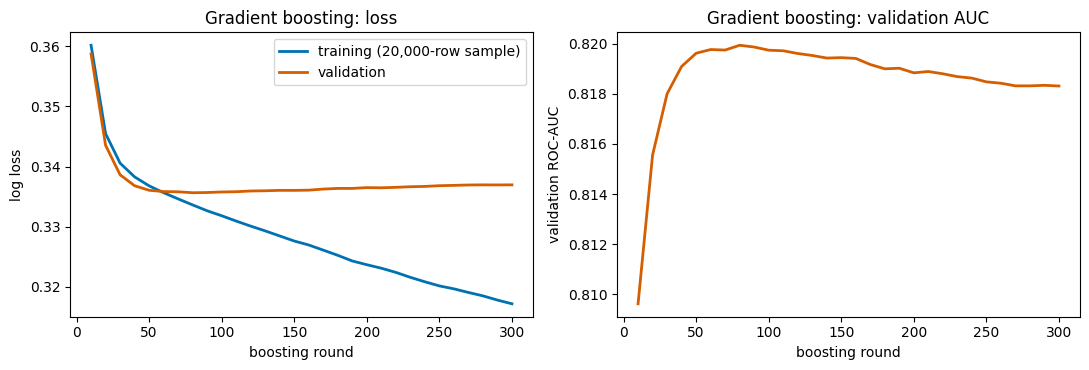

Best validation AUC 0.8199 at round 80; lowest validation loss at round 80


In [29]:
# A boosting model that keeps all 300 rounds (no early stopping), so I can see the whole curve.
# I do not use class weights here: weights shift the predicted probabilities, which would distort the log loss.
boosting_curve_model = HistGradientBoostingClassifier(learning_rate=0.1, max_leaf_nodes=31, max_iter=300, early_stopping=False,
                                                      class_weight=None, random_state=SEED).fit(train_scaled, y_train)

# The training loss is measured on a sample of 20,000 training rows to keep the cell fast.
sample_positions = np.random.RandomState(SEED).choice(len(train_scaled), 20000, replace=False)
train_sample_features = train_scaled.iloc[sample_positions]
train_sample_labels = y_train.iloc[sample_positions]

boosting_rounds, train_loss, val_loss, val_auc = [], [], [], []
# staged_predict_proba gives the predictions of the model after 1 round, after 2 rounds, and so on.
staged_train = boosting_curve_model.staged_predict_proba(train_sample_features)
staged_val = boosting_curve_model.staged_predict_proba(val_scaled)
for round_number, (train_probabilities, val_probabilities) in enumerate(zip(staged_train, staged_val), start=1):
    if round_number % 10 == 0:                      # one point per 10 rounds is enough for the plot
        boosting_rounds.append(round_number)
        train_loss.append(log_loss(train_sample_labels, train_probabilities[:, 1]))
        val_loss.append(log_loss(y_val, val_probabilities[:, 1]))
        val_auc.append(roc_auc_score(y_val, val_probabilities[:, 1]))

experiment_tracker.log_curve("curve_gradient_boosting",
                             {"train_loss": train_loss, "val_loss": val_loss, "val_roc_auc": val_auc}, boosting_rounds)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(boosting_rounds, train_loss, color=BLUE, lw=2, label="training (20,000-row sample)")
axes[0].plot(boosting_rounds, val_loss, color=ORANGE, lw=2, label="validation")
axes[0].set_xlabel("boosting round"); axes[0].set_ylabel("log loss"); axes[0].set_title("Gradient boosting: loss"); axes[0].legend()
axes[1].plot(boosting_rounds, val_auc, color=ORANGE, lw=2)
axes[1].set_xlabel("boosting round"); axes[1].set_ylabel("validation ROC-AUC"); axes[1].set_title("Gradient boosting: validation AUC")
plt.tight_layout()
save_and_show("ml01_boosting_curve")
print(f"Best validation AUC {max(val_auc):.4f} at round {boosting_rounds[int(np.argmax(val_auc))]}; "
      f"lowest validation loss at round {boosting_rounds[int(np.argmin(val_loss))]}")

18:53:27 | curve logged to TensorBoard run 'curve_random_forest': val_roc_auc


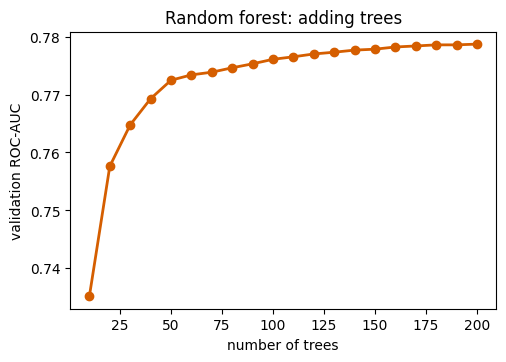

AUC with 10 trees: 0.7351 | with 100 trees: 0.7761 | with 200 trees: 0.7788


In [30]:
# Random forest curve: use only the first k trees of the forest from T03 and average their votes.
forest_trees = traditional_results["T03"]["model"].estimators_
tree_probabilities = np.array([tree.predict_proba(val_scaled.values)[:, 1] for tree in forest_trees])
tree_counts = list(range(10, 201, 10))
forest_auc_by_tree_count = [roc_auc_score(y_val, tree_probabilities[:count].mean(axis=0)) for count in tree_counts]
experiment_tracker.log_curve("curve_random_forest", {"val_roc_auc": forest_auc_by_tree_count}, tree_counts)

plt.figure(figsize=(5.5, 3.6))
plt.plot(tree_counts, forest_auc_by_tree_count, color=ORANGE, lw=2, marker="o")
plt.xlabel("number of trees"); plt.ylabel("validation ROC-AUC"); plt.title("Random forest: adding trees")
save_and_show("ml02_rf_tree_curve")
print(f"AUC with 10 trees: {forest_auc_by_tree_count[0]:.4f} | with 100 trees: {forest_auc_by_tree_count[9]:.4f} | "
      f"with 200 trees: {forest_auc_by_tree_count[-1]:.4f}")

## 5. Hyperparameter tuning
Tuning uses 3-fold cross-validation on the training set only. The validation set is kept for comparing the final models. The tuning metric is ROC-AUC. I use a grid search for logistic regression (few combinations) and a random search for the forest and boosting (many combinations).

In [31]:
# --- Logistic regression: grid over the regularisation strength C and the class weighting ---
logistic_search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=SEED),
                               {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]},
                               scoring="roc_auc", cv=CROSS_VALIDATION, n_jobs=-1)
logistic_search.fit(train_scaled, y_train)
print("Logistic regression, best settings:", logistic_search.best_params_, "| CV ROC-AUC", round(logistic_search.best_score_, 4))

# All grid results are also written to TensorBoard, so the effect of C can be seen (step = position in the grid).
grid_results = pd.DataFrame(logistic_search.cv_results_)[["param_C", "param_class_weight", "mean_test_score"]]
print(grid_results.round(4).to_string(index=False))
experiment_tracker.log_curve("curve_logreg_grid", {"cv_roc_auc": grid_results["mean_test_score"].values}, range(len(grid_results)))

run_experiment("T06", "Logistic regression (tuned)", clone(logistic_search.best_estimator_),
               {**logistic_search.best_params_, "cv_roc_auc": round(logistic_search.best_score_, 4)},
               train_scaled, y_train, val_scaled, y_val, ALL_FEATURES_DESCRIPTION)

18:53:35 | curve logged to TensorBoard run 'curve_logreg_grid': cv_roc_auc


Logistic regression, best settings: {'C': 0.1, 'class_weight': 'balanced'} | CV ROC-AUC 0.8086
 param_C param_class_weight  mean_test_score
    0.01               None           0.8084
    0.01           balanced           0.8086
    0.10               None           0.8086
    0.10           balanced           0.8086
    1.00               None           0.8085
    1.00           balanced           0.8086
   10.00               None           0.8085
   10.00           balanced           0.8086


18:53:35 | T06 | Logistic regression (tuned) | acc 0.719 | precision 0.323 | recall 0.766 | F1 0.454 | ROC-AUC 0.815 | PR-AUC 0.431 | 0.4s


{'accuracy': 0.7188925365329305,
 'precision': 0.32312379730596535,
 'recall': 0.7655775075987842,
 'f1': 0.4544429409111412,
 'roc_auc': np.float64(0.814946703221726),
 'pr_auc': np.float64(0.4305073990701189)}

In [32]:
# --- Random forest: random search, 8 combinations x 3 folds ---
forest_search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    {"max_depth": [8, 12, 16, None], "min_samples_leaf": [1, 5, 20, 50], "max_features": ["sqrt", 0.5]},
    n_iter=8, scoring="roc_auc", cv=CROSS_VALIDATION, random_state=SEED, n_jobs=1)
forest_search.fit(train_scaled, y_train)
print("Random forest, best settings:", forest_search.best_params_, "| CV ROC-AUC", round(forest_search.best_score_, 4))

# class_weight is not part of the search, so I add it to the recorded settings to keep the table complete.
run_experiment("T07", "Random forest (tuned)", clone(forest_search.best_estimator_),
               {**forest_search.best_params_, "n_estimators": 200, "class_weight": "balanced_subsample",
                "cv_roc_auc": round(forest_search.best_score_, 4)},
               train_scaled, y_train, val_scaled, y_val, ALL_FEATURES_DESCRIPTION)

Random forest, best settings: {'min_samples_leaf': 50, 'max_features': 0.5, 'max_depth': 12} | CV ROC-AUC 0.8109


18:57:05 | T07 | Random forest (tuned) | acc 0.724 | precision 0.328 | recall 0.767 | F1 0.460 | ROC-AUC 0.817 | PR-AUC 0.442 | 14.1s


{'accuracy': 0.7240928502948781,
 'precision': 0.3280805783445699,
 'recall': 0.7672872340425532,
 'f1': 0.45963015647226174,
 'roc_auc': np.float64(0.8170261592387424),
 'pr_auc': np.float64(0.4423163665589949)}

In [33]:
# --- Gradient boosting: random search, 10 combinations x 3 folds, with early stopping inside every fit ---
boosting_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", max_iter=300, early_stopping=True, n_iter_no_change=15, random_state=SEED),
    {"learning_rate": [0.03, 0.05, 0.1, 0.2], "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [20, 50, 100],
     "l2_regularization": [0, 0.1, 1, 10]},
    n_iter=10, scoring="roc_auc", cv=CROSS_VALIDATION, random_state=SEED, n_jobs=-1)
boosting_search.fit(train_scaled, y_train)
print("Gradient boosting, best settings:", boosting_search.best_params_, "| CV ROC-AUC", round(boosting_search.best_score_, 4))

run_experiment("T08", "Gradient boosting (tuned)", clone(boosting_search.best_estimator_),
               {**boosting_search.best_params_, "class_weight": "balanced", "cv_roc_auc": round(boosting_search.best_score_, 4)},
               train_scaled, y_train, val_scaled, y_val, ALL_FEATURES_DESCRIPTION)
show_traditional_results(["T01", "T02", "T03", "T04", "T05", "T06", "T07", "T08"])

Gradient boosting, best settings: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'learning_rate': 0.05, 'l2_regularization': 10} | CV ROC-AUC 0.8143


18:57:41 | T08 | Gradient boosting (tuned) | acc 0.708 | precision 0.318 | recall 0.792 | F1 0.454 | ROC-AUC 0.820 | PR-AUC 0.446 | 3.4s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,
T01,Dummy baseline,0.847,0.000,0.000,0.000,0.500,0.153
T02,Logistic regression,0.719,0.323,0.766,0.455,0.815,0.430
T03,Random forest,0.843,0.461,0.156,0.233,0.779,0.358
T04,Gradient boosting,0.710,0.320,0.796,0.457,0.820,0.445
T05,SVM (RBF),0.712,0.317,0.766,0.449,0.799,0.371
T06,Logistic regression (tuned),0.719,0.323,0.766,0.454,0.815,0.431
T07,Random forest (tuned),0.724,0.328,0.767,0.460,0.817,0.442
T08,Gradient boosting (tuned),0.708,0.318,0.792,0.454,0.820,0.446


## 6. Do the new features help?
This is the tuned gradient boosting model (T08) again, but trained on the 21 original features only. The only change is the feature set, so any difference comes from the four new columns.

In [34]:
# A second preprocessing pipeline without the engineered columns, fitted on the training set only, like before.
preprocessor_original_only = build_preprocessor(use_engineered=False).fit(X_train)
train_original_only = transform_to_frame(preprocessor_original_only, X_train)
val_original_only = transform_to_frame(preprocessor_original_only, X_val)
print("Number of features without the engineered columns:", train_original_only.shape[1])

run_experiment("T09", "Gradient boosting (tuned), no engineered features", clone(boosting_search.best_estimator_),
               {**boosting_search.best_params_, "class_weight": "balanced"},
               train_original_only, y_train, val_original_only, y_val, "21 original features",
               fitted_preprocessor=preprocessor_original_only)
show_traditional_results(["T08", "T09"])

Number of features without the engineered columns: 21


18:57:46 | T09 | Gradient boosting (tuned), no engineered features | acc 0.708 | precision 0.318 | recall 0.794 | F1 0.454 | ROC-AUC 0.819 | PR-AUC 0.446 | 5.5s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,
T08,Gradient boosting (tuned),0.708,0.318,0.792,0.454,0.820,0.446
T09,"Gradient boosting (tuned), no engineered features",0.708,0.318,0.794,0.454,0.819,0.446


## 7. Class imbalance: three ways to handle it
All three use the same tuned gradient boosting model.
- T08 (class weights) is the one from section 5.
- T10 (nothing): no class weights at all, to see what happens without any help.
- T11 (SMOTE): artificial diabetes examples are created in the training set only. The validation set stays as it is. SMOTE creates new points between neighbours, so a yes/no column can get an in-between value like 0.37. That is a known weakness when most features are yes/no answers.

In [35]:
# T10: no class weights
run_experiment("T10", "Gradient boosting (tuned), no class weights", clone(boosting_search.best_estimator_).set_params(class_weight=None),
               {**boosting_search.best_params_, "class_weight": "None"}, train_scaled, y_train, val_scaled, y_val,
               ALL_FEATURES_DESCRIPTION)

# T11: SMOTE on the training set, and no class weights (the classes are balanced after SMOTE)
smote_sampler = SMOTE(random_state=SEED)
train_features_smote, train_labels_smote = smote_sampler.fit_resample(train_scaled, y_train)
print(f"Training rows before SMOTE: {len(y_train):,} (diabetes {y_train.mean():.1%}) | "
      f"after: {len(train_labels_smote):,} (diabetes {train_labels_smote.mean():.1%})")
run_experiment("T11", "Gradient boosting (tuned) + SMOTE", clone(boosting_search.best_estimator_).set_params(class_weight=None),
               {**boosting_search.best_params_, "class_weight": "None", "smote_train_rows": len(train_labels_smote)},
               train_features_smote, train_labels_smote, val_scaled, y_val, ALL_FEATURES_DESCRIPTION + ", SMOTE on train")
show_traditional_results(["T08", "T10", "T11"])

18:57:52 | T10 | Gradient boosting (tuned), no class weights | acc 0.855 | precision 0.584 | recall 0.171 | F1 0.264 | ROC-AUC 0.820 | PR-AUC 0.445 | 5.2s


Training rows before SMOTE: 160,631 (diabetes 15.3%) | after: 272,126 (diabetes 50.0%)


18:58:02 | T11 | Gradient boosting (tuned) + SMOTE | acc 0.852 | precision 0.535 | recall 0.255 | F1 0.345 | ROC-AUC 0.818 | PR-AUC 0.443 | 8.7s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,
T08,Gradient boosting (tuned),0.708,0.318,0.792,0.454,0.820,0.446
T10,"Gradient boosting (tuned), no class weights",0.855,0.584,0.171,0.264,0.820,0.445
T11,Gradient boosting (tuned) + SMOTE,0.852,0.535,0.255,0.345,0.818,0.443


## 8. Comparing everything

In [36]:
experiment_table = experiment_tracker.read()
metrics_overview = experiment_table[["exp_id", "model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_seconds"]]
metrics_overview.sort_values("roc_auc", ascending=False).reset_index(drop=True)

,exp_id,model,accuracy,precision,recall,f1,roc_auc,pr_auc,train_seconds
0,T10,"Gradient boosting (tuned), no class weights",0.8546,0.5843,0.1706,0.2641,0.8200,0.4453,5.2
1,T08,Gradient boosting (tuned),0.7083,0.3179,0.7920,0.4536,0.8199,0.4457,3.4
2,D04,Neural net 64-32 + dropout 0.3,0.8544,0.6250,0.1206,0.2022,0.8199,0.4440,35.5
3,T04,Gradient boosting,0.7105,0.3203,0.7956,0.4567,0.8197,0.4447,2.2
4,D01,Neural net 64-32,0.8556,0.6060,0.1601,0.2533,0.8196,0.4430,13.9
5,D11,Neural net 64-32 + dropout 0.3 + class weights,0.6981,0.3122,0.8093,0.4506,0.8195,0.4432,40.2
6,D10,Neural net 64-32 + class weights,0.7069,0.3169,0.7935,0.4530,0.8195,0.4406,18.1
7,T09,"Gradient boosting (tuned), no engineered features",0.7079,0.3178,0.7939,0.4539,0.8195,0.4455,5.5
8,D07,Neural net 64-32 + rmsprop,0.8553,0.5853,0.1850,0.2812,0.8195,0.4454,13.5
9,D08,Neural net 64-32 + lr 0.01,0.8552,0.5907,0.1738,0.2686,0.8193,0.4399,17.2


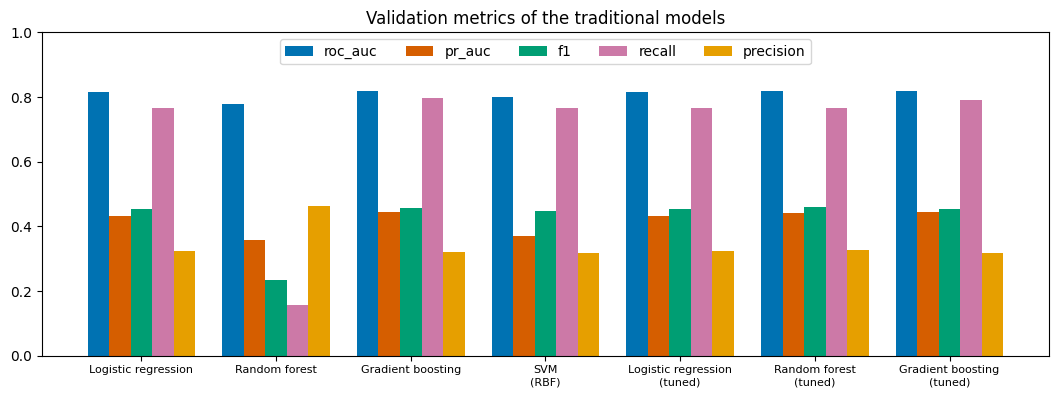

In [37]:
# Bar chart of the main metrics for the models trained on all the features
main_experiment_ids = ["T02", "T03", "T04", "T05", "T06", "T07", "T08"]
metrics_to_plot = ["roc_auc", "pr_auc", "f1", "recall", "precision"]
model_labels = [traditional_results[experiment_id]["name"].replace(" (", "\n(") for experiment_id in main_experiment_ids]
bar_colors = [BLUE, ORANGE, "#009E73", "#CC79A7", "#E69F00"]

fig, ax = plt.subplots(figsize=(13, 4.2))
bar_width = 0.16
for metric_number, metric in enumerate(metrics_to_plot):
    metric_values = [traditional_results[experiment_id]["metrics"][metric] for experiment_id in main_experiment_ids]
    ax.bar(np.arange(len(main_experiment_ids)) + (metric_number - 2) * bar_width, metric_values, bar_width,
           label=metric, color=bar_colors[metric_number])
ax.set_xticks(range(len(main_experiment_ids))); ax.set_xticklabels(model_labels, fontsize=8)
ax.set_ylim(0, 1); ax.set_title("Validation metrics of the traditional models"); ax.legend(ncol=5, loc="upper center")
save_and_show("ml03_model_comparison")

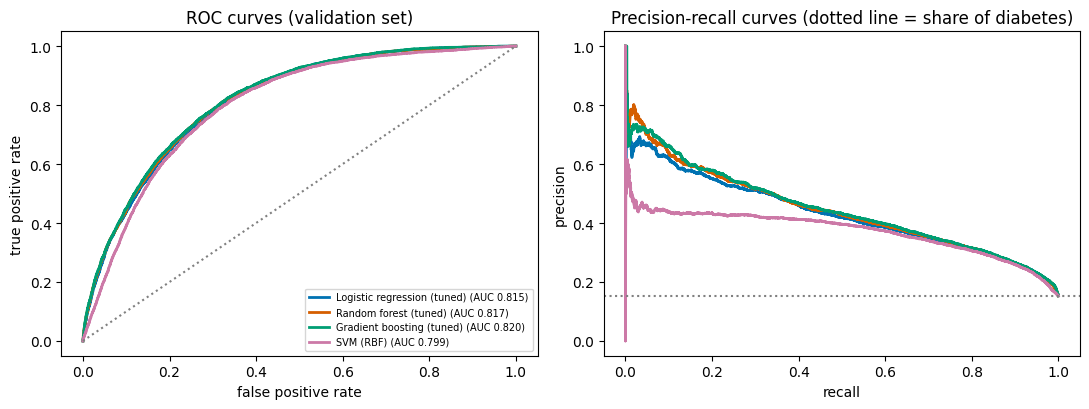

In [38]:
# ROC curves and precision-recall curves of the tuned models and the SVM
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for experiment_id, color in [("T06", BLUE), ("T07", ORANGE), ("T08", "#009E73"), ("T05", "#CC79A7")]:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_val, traditional_results[experiment_id]["scores"])
    precision_values, recall_values, _ = precision_recall_curve(y_val, traditional_results[experiment_id]["scores"])
    curve_label = f"{traditional_results[experiment_id]['name']} (AUC {traditional_results[experiment_id]['metrics']['roc_auc']:.3f})"
    axes[0].plot(false_positive_rate, true_positive_rate, color=color, lw=2, label=curve_label)
    axes[1].plot(recall_values, precision_values, color=color, lw=2)
axes[0].plot([0, 1], [0, 1], ":", color="grey"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curves (validation set)"); axes[0].legend(fontsize=7, loc="lower right")
axes[1].axhline(y_val.mean(), color="grey", ls=":"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves (dotted line = share of diabetes)")
plt.tight_layout()
save_and_show("ml04_roc_pr_curves")

## 9. Learning curve for the best type of model
How much does the score improve when the model sees more training data? If both curves are flat and close together, more data will not help much. A large gap means the model overfits.

19:00:08 | curve logged to TensorBoard run 'curve_learning_size_gradient_boosting': train_roc_auc, cv_roc_auc


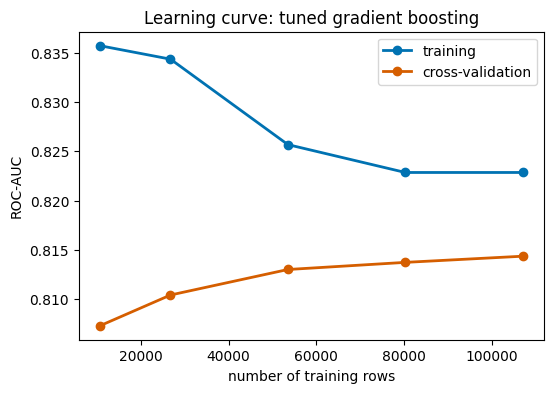

  rows  train AUC  CV AUC
 10708     0.8357  0.8073
 26771     0.8344  0.8104
 53543     0.8257  0.8130
 80315     0.8229  0.8137
107087     0.8229  0.8144


In [39]:
training_sizes, train_auc_by_size, cv_auc_by_size = learning_curve(
    clone(boosting_search.best_estimator_), train_scaled, y_train,
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], cv=CROSS_VALIDATION, scoring="roc_auc", n_jobs=-1)
experiment_tracker.log_curve("curve_learning_size_gradient_boosting",
                             {"train_roc_auc": train_auc_by_size.mean(axis=1), "cv_roc_auc": cv_auc_by_size.mean(axis=1)}, training_sizes)

plt.figure(figsize=(6, 4))
plt.plot(training_sizes, train_auc_by_size.mean(axis=1), color=BLUE, marker="o", lw=2, label="training")
plt.plot(training_sizes, cv_auc_by_size.mean(axis=1), color=ORANGE, marker="o", lw=2, label="cross-validation")
plt.xlabel("number of training rows"); plt.ylabel("ROC-AUC"); plt.title("Learning curve: tuned gradient boosting"); plt.legend()
save_and_show("ml05_learning_curve_size")
print(pd.DataFrame({"rows": training_sizes, "train AUC": train_auc_by_size.mean(axis=1).round(4),
                    "CV AUC": cv_auc_by_size.mean(axis=1).round(4)}).to_string(index=False))

## 10. Choose and save the best traditional model
The best model is the one with the highest validation ROC-AUC among the SVM and the three tuned models. The test set plays no role. I fixed this rule before looking at the results, because several models differ only in the fourth decimal. I save the preprocessing together with the model, so the saved file accepts the raw answer columns (with the four engineered columns added by `add_features`).

In [40]:
# The rule is fixed before looking at the results: the best validation ROC-AUC among the SVM and the three tuned models.
# T09 to T11 reuse the tuned boosting model and change one thing each, so they answer questions about
# the features and the imbalance. They are not separate contenders.
candidate_ids = ["T05", "T06", "T07", "T08"]
best_traditional_id = max(candidate_ids, key=lambda experiment_id: traditional_results[experiment_id]["metrics"]["roc_auc"])
best_traditional = traditional_results[best_traditional_id]
print(f"Best traditional model: {best_traditional_id} - {best_traditional['name']}")
print({metric: round(float(value), 4) for metric, value in best_traditional["metrics"].items()})
print("The others:", {experiment_id: round(float(traditional_results[experiment_id]["metrics"]["roc_auc"]), 4)
                      for experiment_id in candidate_ids if experiment_id != best_traditional_id})

# ToDataFrame puts the column names back, because the model was trained on a table with named columns.
column_names = list(transform_to_frame(best_traditional["preprocessor"], X_val.head(1)).columns)
best_pipeline = Pipeline([("prep", best_traditional["preprocessor"]), ("to_frame", ToDataFrame(column_names)),
                          ("model", best_traditional["model"])])
joblib.dump(best_pipeline, MODELS_DIR / "best_traditional_model.joblib")

# Reload the file and check that it gives the same scores on the raw validation data.
reloaded_pipeline = joblib.load(MODELS_DIR / "best_traditional_model.joblib")
if hasattr(reloaded_pipeline, "predict_proba"):
    reloaded_scores = reloaded_pipeline.predict_proba(X_val)[:, 1]
else:
    reloaded_scores = reloaded_pipeline.decision_function(X_val)
print("Largest difference after reloading:", float(np.abs(reloaded_scores - best_traditional["scores"]).max()))

Best traditional model: T08 - Gradient boosting (tuned)
{'accuracy': 0.7083, 'precision': 0.3179, 'recall': 0.792, 'f1': 0.4536, 'roc_auc': 0.8199, 'pr_auc': 0.4457}
The others: {'T05': 0.7995, 'T06': 0.8149, 'T07': 0.817}
Largest difference after reloading: 0.0


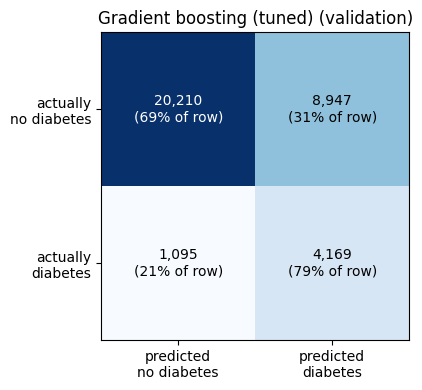

In [41]:
# Confusion matrix of the best traditional model on the validation set (cut-off 0.5)
confusion = confusion_matrix(y_val, best_traditional["predictions"])
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(confusion, cmap="Blues"); ax.grid(False)
for row in range(2):
    for column in range(2):
        ax.text(column, row, f"{confusion[row, column]:,}\n({confusion[row, column] / confusion[row].sum():.0%} of row)",
                ha="center", va="center", color="white" if confusion[row, column] > confusion.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["predicted\nno diabetes", "predicted\ndiabetes"]); ax.set_yticklabels(["actually\nno diabetes", "actually\ndiabetes"])
ax.set_title(f"{best_traditional['name']} (validation)")
save_and_show("ml06_confusion_matrix_best")

## 11. Observations for the experiment table
A short note for each run, written into `reports/experiment_log.csv`. They only state what the numbers show. In the report I put them in my own words and add the reasons.

In [42]:
traditional_observations = {
    "T01": "Accuracy 0.847 only because it answers 'no diabetes' for everyone. Recall 0, F1 0, ROC-AUC 0.50. This shows that accuracy is misleading on this data.",
    "T02": "Class-weighted linear model: ROC-AUC 0.815, recall 0.77 but precision only 0.32. It trains in under a second. A strong and cheap reference point.",
    "T03": "Forest with unlimited depth: ROC-AUC 0.779 and recall only 0.16 at the 0.5 cut-off. The AUC rose from 0.735 (10 trees) to 0.776 (100) and 0.779 (200), so more trees help little. Tuning (T07) closed most of the gap by using shallower trees.",
    "T04": "The default boosting model is already the best untuned model: ROC-AUC 0.820 and PR-AUC 0.445, trained in a few seconds.",
    "T05": "SVM trained on 20,000 rows (about 12% of the training set): ROC-AUC 0.800. This is not a fair comparison with the models that use all the data, and the cost of an SVM grows quickly with the number of rows.",
    "T06": "Tuning changed nothing: C from 0.01 to 10 and the class weighting gave a CV ROC-AUC between 0.8084 and 0.8086. The limit comes from the linear form of the model, not from the regularisation.",
    "T07": "Best settings: max_depth 12, min_samples_leaf 50, max_features 0.5. The ROC-AUC rose from 0.779 (T03) to 0.817, and its F1 of 0.460 is the highest of all runs. Shallower, smoother trees reduced the overfitting of T03.",
    "T08": "Best traditional model: learning_rate 0.05, max_leaf_nodes 15, min_samples_leaf 20, l2 10. ROC-AUC 0.8199, PR-AUC 0.4457. The gain over the default model T04 is only 0.0002 in AUC, so tuning barely mattered.",
    "T09": "The same model without the 4 engineered features: ROC-AUC 0.8195 against 0.8199 and PR-AUC 0.4455 against 0.4457. No measurable benefit from the new features on this split. The run-to-run variation is measured in Step 6.",
    "T10": "Without class weights the ranking quality is the same (ROC-AUC 0.8200), but the recall falls from 0.79 to 0.17 while the precision rises from 0.32 to 0.58 and the accuracy to 0.855. Class weights change the balance of the errors at the 0.5 cut-off, not how well people are ranked.",
    "T11": "SMOTE on the training set only: ROC-AUC 0.818, recall 0.25, precision 0.54. It moves the balance of the errors less than class weights do, and the AUC is slightly lower than T08."
}

experiment_tracker.set_observations(traditional_observations)
experiment_tracker.read()[["exp_id", "model", "roc_auc", "observations"]]

,exp_id,model,roc_auc,observations
0,D01,Neural net 64-32,0.8196,"Baseline. Validation ROC-AUC 0.8196, best epoc..."
1,D02,Neural net 128-64-32,0.8190,Wider and deeper: ROC-AUC 0.8190 (-0.0006 agai...
2,D03,Neural net 32,0.8191,One hidden layer of 32: ROC-AUC 0.8191 (-0.000...
3,D04,Neural net 64-32 + dropout 0.3,0.8199,Dropout 0.3: ROC-AUC 0.8199 (+0.0003 against D...
4,D05,Neural net 64-32 + batch norm,0.8181,Batch normalization: ROC-AUC 0.8181 (-0.0015 a...
5,D06,Neural net 64-32 + sgd + lr 0.01,0.8191,SGD with momentum (learning rate 0.01): ROC-AU...
6,D07,Neural net 64-32 + rmsprop,0.8195,"RMSprop: ROC-AUC 0.8195, PR-AUC 0.4454. Very c..."
7,D08,Neural net 64-32 + lr 0.01,0.8193,Adam with a 10 times bigger learning rate (0.0...
8,D09,Neural net 64-32 + lr 0.0001,0.8189,Adam with a 10 times smaller learning rate (0....
9,D10,Neural net 64-32 + class weights,0.8195,Class weights: ROC-AUC 0.8195 (the same rankin...


## 12. Looking at the logs in TensorBoard
In a terminal, from the project folder:
```
.venv/bin/tensorboard --logdir logs/tensorboard
```
Then open http://localhost:6006. The HParams tab lists every experiment with its settings and metrics, and you can sort it. The Scalars tab shows the `curve_` runs: the boosting loss and AUC per round, the forest AUC per number of trees, the logistic regression grid and the learning curve.

In [43]:
print("TensorBoard runs written so far:", len(list((LOGS_DIR / "tensorboard").iterdir())))
print("Experiment table:", (REPORTS_DIR / "experiment_log.csv").relative_to(ROOT), "| text log:", (LOGS_DIR / "step4_traditional_ml.log").relative_to(ROOT))

TensorBoard runs written so far: 28
Experiment table: reports/experiment_log.csv | text log: logs/step4_traditional_ml.log


## 13. Summary of Step 4

What the output above shows:
- The best traditional model is T08, the tuned gradient boosting model. On the validation set it has a ROC-AUC of 0.820, a PR-AUC of 0.446, an F1 of 0.454, a recall of 0.79 and a precision of 0.32. It is saved as `models/best_traditional_model.joblib`, and reloading it gives identical scores.
- Every reasonable model ends up with a ROC-AUC between 0.80 and 0.82. Only the untuned forest (0.779) and the SVM trained on a small sample (0.800) are lower. Tuning made little difference for logistic regression and for boosting, and a large difference for the forest (0.779 to 0.817).
- Boosting curve: the validation AUC peaks around round 80 and then slowly goes down, while the training loss keeps falling and the validation loss stays flat. This is mild overfitting after about 80 rounds.
- Learning curve for the training size: with all the training data the training AUC is 0.823 and the cross-validated AUC is 0.814. The gap is small, and going from 10% to 100% of the data raises the CV AUC by only about 0.007.
- The four engineered features gave no measurable gain (AUC 0.8199 with them and 0.8195 without).
- Class weights, no weights and SMOTE give almost the same ROC-AUC. They differ in how the errors are split. With class weights the model finds 79% of the diabetes cases, but about two out of three of its "diabetes" predictions are false alarms. Without weights it finds only 17%, with a higher precision.
- The test set has not been used yet.

Questions I answer in my own words before the report:
1. Why might all the models stop at a ROC-AUC of about 0.82? (Think about what 21 survey answers can and cannot tell, and about the label noise from Step 3.)
2. For a screening tool, what matters more, recall or precision? Which setting from T08, T10 or T11 would I choose, and why?
3. Why might the engineered features have added nothing, even though they showed a clear pattern in the plot?

---
# Step 5: Deep learning (TensorFlow / Keras)

A neural network is a stack of layers. Each layer multiplies its inputs by weights, adds a bias and applies an activation function. The first layer receives the 25 features of one person, and the last layer gives one number between 0 and 1: the predicted probability of diabetes. During training the network looks at a small group of people (a batch), measures its error with a loss function, and changes its weights a little to reduce that error. The optimizer decides how the weights are changed. One pass over all the training rows is called an epoch.

The model I build uses the Keras Sequential API:

| Part | My choice | Why |
|---|---|---|
| Input | 25 numbers (the scaled features from Step 3) | The same data as the scikit-learn models, so the comparison is fair |
| Hidden layers | `Dense` layers with ReLU activation | ReLU is the standard, simple choice for tabular data |
| Output | 1 neuron with a sigmoid | There are two classes, so one probability between 0 and 1 is enough |
| Loss | binary cross-entropy | The usual loss for a yes/no target |
| Metrics | AUC, precision, recall, accuracy | Accuracy alone is misleading on imbalanced data |

The data goes into the network through a `tf.data` pipeline. It shuffles the training rows in every epoch, groups them into batches of 256, and prepares the next batch while the current one is being used.

Safeguards during training (callbacks):
- `EarlyStopping` stops when the validation AUC has not improved for 6 epochs and goes back to the best epoch. This limits overfitting.
- `ModelCheckpoint` saves the best version of the model during training.
- `ReduceLROnPlateau` halves the learning rate when the progress stalls.
- `TensorBoard` and `CSVLogger` record the loss and the metrics of every epoch in `logs/`.

The experiment plan changes one thing at a time compared with a simple baseline (D01), so any difference can be linked to that change. The last experiment (D11) combines two of the changes, chosen for a clear reason (see section 7).

| ID | What changes compared with D01 (layers 64-32, Adam, learning rate 0.001, no dropout) |
|---|---|
| D01 | The baseline |
| D02 | Wider and deeper: 128-64-32 |
| D03 | Smaller: one layer of 32 |
| D04 | Dropout 0.3 (randomly switches off neurons during training, to reduce overfitting) |
| D05 | Batch normalization (rescales the output of each layer, can make training steadier) |
| D06 | Optimizer SGD with momentum (learning rate 0.01) |
| D07 | Optimizer RMSprop |
| D08 | Learning rate 0.01 (10 times bigger) |
| D09 | Learning rate 0.0001 (10 times smaller) |
| D10 | Class weights (a person with diabetes counts more in the loss) |
| D11 | Dropout 0.3 and class weights together |

As in Step 4, every network is trained on the training set and compared on the validation set. The test set stays untouched.

## 1. Setup

In [44]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

BATCH_SIZE = 256        # how many people the network looks at before it updates its weights
MAX_EPOCHS = 40         # an upper limit. Early stopping usually stops sooner.

CHECKPOINT_DIR = MODELS_DIR / "checkpoints"
CSV_LOG_DIR = LOGS_DIR / "training_csv"
CHECKPOINT_DIR.mkdir(exist_ok=True)
CSV_LOG_DIR.mkdir(exist_ok=True)

# A new tracker for this step: the same experiment table and TensorBoard folder, but its own text log.
experiment_tracker = ExperimentTracker(REPORTS_DIR / "experiment_log.csv", LOGS_DIR / "tensorboard",
                                       LOGS_DIR / "step5_deep_learning.log")

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.18.0 | Keras 3.15.1


## 2. Helper functions
Three small functions keep the experiments short:
1. `make_dataset` builds the `tf.data` pipeline.
2. `build_model` creates the network from a list of layer sizes.
3. `run_network_experiment` builds, trains and evaluates one network and records it (CSV table, text log and TensorBoard).

In [45]:
def make_dataset(features, labels, shuffle):
    # Turn the tables of features and labels into a tf.data pipeline.
    dataset = tf.data.Dataset.from_tensor_slices((features.values.astype("float32"), labels.values.astype("float32")))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(labels), seed=SEED)   # mix the rows, for training only
    dataset = dataset.batch(BATCH_SIZE)                                 # groups of 256 people
    dataset = dataset.prefetch(tf.data.AUTOTUNE)                        # prepare the next batch in advance
    return dataset


def build_model(n_features, hidden_layers, dropout=0.0, batch_norm=False):
    # Build a network: input -> hidden layers -> one sigmoid output neuron.
    model = keras.Sequential()
    model.add(keras.Input(shape=(n_features,)))
    for units in hidden_layers:
        model.add(layers.Dense(units))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return model


def make_optimizer(optimizer_name, learning_rate):
    # Choose the optimizer by its name.
    if optimizer_name == "adam":
        return keras.optimizers.Adam(learning_rate)
    if optimizer_name == "sgd":
        return keras.optimizers.SGD(learning_rate, momentum=0.9)
    if optimizer_name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate)
    raise ValueError("unknown optimizer: " + optimizer_name)


train_dataset = make_dataset(train_scaled, y_train, shuffle=True)
val_dataset = make_dataset(val_scaled, y_val, shuffle=False)     # no shuffling, so the predictions stay in the same order as y_val
print("Batches per epoch:", len(train_dataset), "| validation batches:", len(val_dataset))

Batches per epoch: 628 | validation batches: 135


In [46]:
network_results = {}      # experiment id -> the trained network, its scores, its training history and its metrics


def run_network_experiment(experiment_id, hidden_layers, dropout=0.0, batch_norm=False, optimizer="adam",
                           learning_rate=0.001, use_class_weights=False):
    # Build, train and evaluate one network, then record it.
    keras.utils.set_random_seed(SEED)                  # the same starting weights in every experiment

    # The model name says what is different from the baseline, so the experiment table is easy to read.
    layer_text = "-".join(str(units) for units in hidden_layers)
    model_name = f"Neural net {layer_text}"
    if dropout > 0:
        model_name += f" + dropout {dropout}"
    if batch_norm:
        model_name += " + batch norm"
    if optimizer != "adam":
        model_name += f" + {optimizer}"
    if learning_rate != 0.001:
        model_name += f" + lr {learning_rate}"
    if use_class_weights:
        model_name += " + class weights"

    # Empty TensorBoard folder for this run. Keras writes the epoch-by-epoch curves into it.
    tensorboard_folder = experiment_tracker.reset_run(experiment_tracker.run_name(experiment_id, model_name))

    model = build_model(train_scaled.shape[1], hidden_layers, dropout, batch_norm)
    model.compile(optimizer=make_optimizer(optimizer, learning_rate),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"), "accuracy"])

    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(CHECKPOINT_DIR / f"{experiment_id}.keras", monitor="val_auc", mode="max", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=3),
        keras.callbacks.TensorBoard(log_dir=str(tensorboard_folder)),
        keras.callbacks.CSVLogger(str(CSV_LOG_DIR / f"{experiment_id}.csv")),
    ]

    start_time = time.time()
    # shuffle=False because the tf.data pipeline already shuffles the training rows in every epoch.
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=MAX_EPOCHS, verbose=0, shuffle=False,
                        class_weight=class_weights if use_class_weights else None, callbacks=callbacks)
    seconds = time.time() - start_time

    # After early stopping, the model holds the weights of its best epoch.
    scores = model.predict(val_dataset, verbose=0).ravel()
    metrics = evaluate_binary(y_val.values, scores)
    best_epoch = int(np.argmax(history.history["val_auc"])) + 1

    settings = {"hidden_layers": layer_text, "dropout": dropout, "batch_norm": batch_norm, "optimizer": optimizer,
                "learning_rate": learning_rate, "class_weights": use_class_weights, "batch_size": BATCH_SIZE,
                "epochs_run": len(history.history["loss"]), "best_epoch": best_epoch}
    experiment_tracker.log_experiment(experiment_id, "5 deep learning", model_name, settings, ALL_FEATURES_DESCRIPTION,
                                      SPLIT_DESCRIPTION, f"validation ({len(y_val):,} rows)", metrics, seconds,
                                      keep_existing_run=True)
    network_results[experiment_id] = {"name": model_name, "model": model, "scores": scores, "history": history.history,
                                      "metrics": metrics, "settings": settings}
    return metrics


def show_network_results(experiment_ids):
    # A small table with the results of some networks.
    rows = []
    for experiment_id in experiment_ids:
        settings = network_results[experiment_id]["settings"]
        rows.append({"experiment": experiment_id, "layers": settings["hidden_layers"], "epochs": settings["epochs_run"],
                     "best epoch": settings["best_epoch"],
                     **{metric: round(value, 3) for metric, value in network_results[experiment_id]["metrics"].items()}})
    return pd.DataFrame(rows).set_index("experiment")

## 3. Experiments D01 to D03: the baseline and the size of the network

In [47]:
# D01: the baseline, two hidden layers (64 and 32 neurons), Adam, learning rate 0.001
run_network_experiment("D01", hidden_layers=(64, 32))

# D02: a wider and deeper network
run_network_experiment("D02", hidden_layers=(128, 64, 32))

# D03: a smaller network with a single hidden layer
run_network_experiment("D03", hidden_layers=(32,))

show_network_results(["D01", "D02", "D03"])

19:00:24 | D01 | Neural net 64-32 | acc 0.856 | precision 0.606 | recall 0.160 | F1 0.253 | ROC-AUC 0.820 | PR-AUC 0.443 | 14.8s


19:00:45 | D02 | Neural net 128-64-32 | acc 0.854 | precision 0.575 | recall 0.173 | F1 0.266 | ROC-AUC 0.819 | PR-AUC 0.439 | 20.8s


19:01:11 | D03 | Neural net 32 | acc 0.855 | precision 0.597 | recall 0.156 | F1 0.248 | ROC-AUC 0.819 | PR-AUC 0.441 | 25.7s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.820,0.443
D02,128-64-32,16,10,0.854,0.575,0.173,0.266,0.819,0.439
D03,32,28,22,0.855,0.597,0.156,0.248,0.819,0.441


## 4. Experiments D04 and D05: regularization against overfitting
Both start from the baseline D01 and add one technique.

In [48]:
# D04: dropout of 0.3 after every hidden layer
run_network_experiment("D04", hidden_layers=(64, 32), dropout=0.3)

# D05: batch normalization after every hidden layer
run_network_experiment("D05", hidden_layers=(64, 32), batch_norm=True)

show_network_results(["D01", "D04", "D05"])

19:01:48 | D04 | Neural net 64-32 + dropout 0.3 | acc 0.854 | precision 0.625 | recall 0.121 | F1 0.202 | ROC-AUC 0.820 | PR-AUC 0.444 | 37.2s


19:02:04 | D05 | Neural net 64-32 + batch norm | acc 0.854 | precision 0.572 | recall 0.186 | F1 0.280 | ROC-AUC 0.818 | PR-AUC 0.440 | 15.6s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.820,0.443
D04,64-32,31,25,0.854,0.625,0.121,0.202,0.820,0.444
D05,64-32,12,6,0.854,0.572,0.186,0.280,0.818,0.440


## 5. Experiments D06 to D09: optimizer and learning rate
The optimizer decides how the weights are updated, and the learning rate decides how big each update is.

In [49]:
# D06: SGD with momentum (it needs a bigger learning rate than Adam)
run_network_experiment("D06", hidden_layers=(64, 32), optimizer="sgd", learning_rate=0.01)

# D07: RMSprop
run_network_experiment("D07", hidden_layers=(64, 32), optimizer="rmsprop", learning_rate=0.001)

# D08: Adam with a learning rate 10 times bigger
run_network_experiment("D08", hidden_layers=(64, 32), learning_rate=0.01)

# D09: Adam with a learning rate 10 times smaller
run_network_experiment("D09", hidden_layers=(64, 32), learning_rate=0.0001)

show_network_results(["D01", "D06", "D07", "D08", "D09"])

19:02:31 | D06 | Neural net 64-32 + sgd + lr 0.01 | acc 0.854 | precision 0.572 | recall 0.185 | F1 0.279 | ROC-AUC 0.819 | PR-AUC 0.441 | 26.3s


19:02:45 | D07 | Neural net 64-32 + rmsprop | acc 0.855 | precision 0.585 | recall 0.185 | F1 0.281 | ROC-AUC 0.820 | PR-AUC 0.445 | 13.7s


19:03:02 | D08 | Neural net 64-32 + lr 0.01 | acc 0.855 | precision 0.591 | recall 0.174 | F1 0.269 | ROC-AUC 0.819 | PR-AUC 0.440 | 16.5s


19:03:43 | D09 | Neural net 64-32 + lr 0.0001 | acc 0.854 | precision 0.586 | recall 0.162 | F1 0.254 | ROC-AUC 0.819 | PR-AUC 0.441 | 41.4s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.820,0.443
D06,64-32,26,20,0.854,0.572,0.185,0.279,0.819,0.441
D07,64-32,13,7,0.855,0.585,0.185,0.281,0.820,0.445
D08,64-32,16,10,0.855,0.591,0.174,0.269,0.819,0.440
D09,64-32,40,40,0.854,0.586,0.162,0.254,0.819,0.441


## 6. Experiment D10: class weights
The same idea as in Step 4: every person with diabetes counts more in the loss (the weights 0.59 and 3.27 from Step 3).

In [50]:
run_network_experiment("D10", hidden_layers=(64, 32), use_class_weights=True)
show_network_results(["D01", "D10"])

19:04:01 | D10 | Neural net 64-32 + class weights | acc 0.707 | precision 0.317 | recall 0.794 | F1 0.453 | ROC-AUC 0.820 | PR-AUC 0.441 | 17.2s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.82,0.443
D10,64-32,16,10,0.707,0.317,0.794,0.453,0.82,0.441


## 7. Experiment D11: combining two changes
After D01 to D10 (validation results only), none of the single changes moved the ROC-AUC by more than about 0.001, so choosing by AUC would only follow noise. I combine two changes that each have a clear purpose. Dropout is the standard protection against overfitting, and it had the best AUC by a tiny margin. Class weights are the only change that clearly changed recall and precision.

In [51]:
run_network_experiment("D11", hidden_layers=(64, 32), dropout=0.3, use_class_weights=True)
show_network_results(["D01", "D11"])

19:04:37 | D11 | Neural net 64-32 + dropout 0.3 + class weights | acc 0.698 | precision 0.312 | recall 0.809 | F1 0.451 | ROC-AUC 0.820 | PR-AUC 0.443 | 36.5s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
experiment,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.82,0.443
D11,64-32,29,23,0.698,0.312,0.809,0.451,0.82,0.443


## 8. Learning curves
A learning curve shows the loss and the AUC after each epoch, for the training data and for the validation data.
- Both curves get better together: the network is still learning.
- The training curve keeps getting better but the validation curve stalls or gets worse: the network is overfitting, which means it is memorising the training rows.
- Both curves are poor: the network is underfitting, which means it is too simple or trained too little.

One caution: Keras measures the training curve while the weights are still changing during the epoch (and with dropout switched on). It can therefore look a little worse than the validation curve. That is normal.

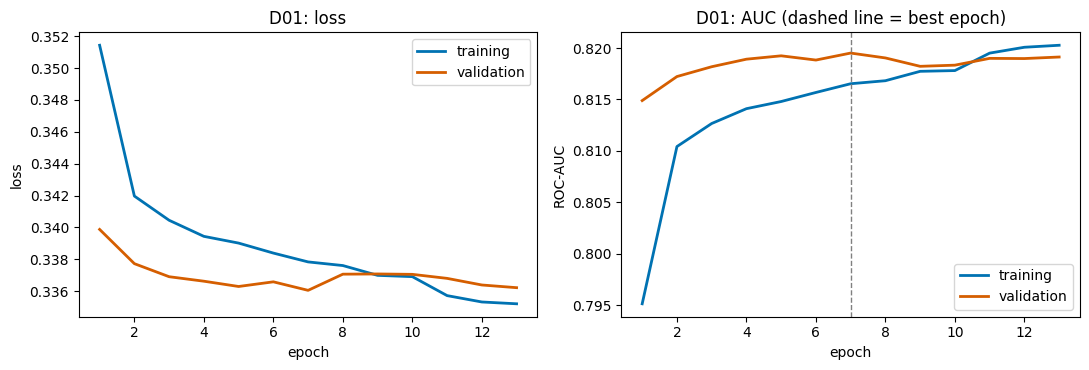

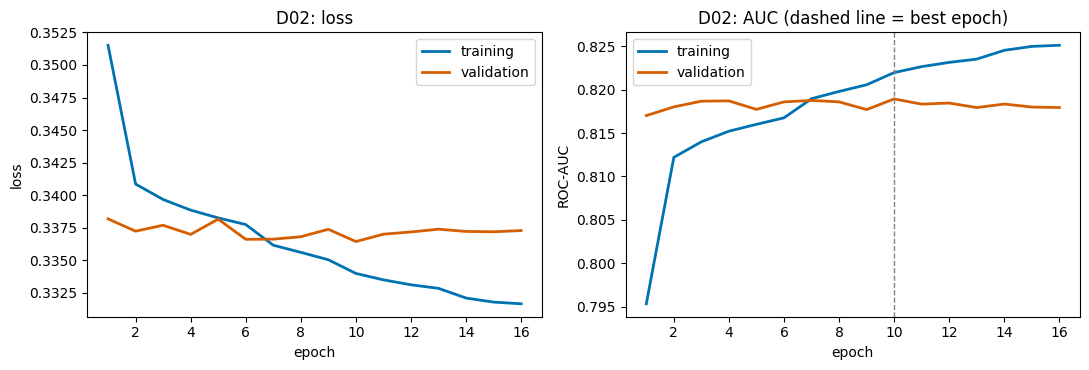

In [52]:
def plot_learning_curves(experiment_id):
    # The loss and the AUC per epoch, training against validation.
    history_values = network_results[experiment_id]["history"]
    epochs = range(1, len(history_values["loss"]) + 1)
    best_epoch = network_results[experiment_id]["settings"]["best_epoch"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(epochs, history_values["loss"], color=BLUE, lw=2, label="training")
    axes[0].plot(epochs, history_values["val_loss"], color=ORANGE, lw=2, label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title(f"{experiment_id}: loss"); axes[0].legend()
    axes[1].plot(epochs, history_values["auc"], color=BLUE, lw=2, label="training")
    axes[1].plot(epochs, history_values["val_auc"], color=ORANGE, lw=2, label="validation")
    axes[1].axvline(best_epoch, color="grey", ls="--", lw=1)
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("ROC-AUC"); axes[1].set_title(f"{experiment_id}: AUC (dashed line = best epoch)"); axes[1].legend()
    plt.tight_layout()
    save_and_show(f"dl_learning_curves_{experiment_id}")


plot_learning_curves("D01")      # the baseline
plot_learning_curves("D02")      # the biggest network

In [53]:
# The numbers behind the curves: how big is the gap between training and validation at the best epoch?
gap_rows = []
for experiment_id, result in network_results.items():
    history_values = result["history"]
    best_index = result["settings"]["best_epoch"] - 1
    gap_rows.append({"experiment": experiment_id, "best epoch": best_index + 1,
                     "train AUC": round(history_values["auc"][best_index], 4), "val AUC": round(history_values["val_auc"][best_index], 4),
                     "gap": round(history_values["auc"][best_index] - history_values["val_auc"][best_index], 4),
                     "train loss": round(history_values["loss"][best_index], 4), "val loss": round(history_values["val_loss"][best_index], 4)})
pd.DataFrame(gap_rows).set_index("experiment")

,best epoch,train AUC,val AUC,gap,train loss,val loss
experiment,,,,,,
D01,7,0.8165,0.8195,-0.0030,0.3378,0.3361
D02,10,0.8220,0.8189,0.0030,0.3340,0.3364
D03,22,0.8177,0.8191,-0.0014,0.3370,0.3364
D04,25,0.8133,0.8198,-0.0065,0.3407,0.3361
D05,6,0.8163,0.8181,-0.0018,0.3380,0.3372
D06,20,0.8177,0.8191,-0.0013,0.3370,0.3364
D07,7,0.8161,0.8195,-0.0033,0.3380,0.3360
D08,10,0.8176,0.8193,-0.0017,0.3372,0.3370
D09,40,0.8174,0.8189,-0.0014,0.3371,0.3364


## 9. Choose the best neural network
The rule is fixed before looking at the results: the network with the highest validation ROC-AUC among D01 to D11. The test set is not used. If several networks are within 0.001 AUC of the best one, they are practically tied, and I say so in the report.

Best neural network: D04 - Neural net 64-32 + dropout 0.3
{'accuracy': 0.8544, 'precision': 0.625, 'recall': 0.1206, 'f1': 0.2022, 'roc_auc': 0.8199, 'pr_auc': 0.444}
Networks within 0.001 AUC of the best one: {'D01': 0.8196, 'D02': 0.819, 'D03': 0.8191, 'D06': 0.8191, 'D07': 0.8195, 'D08': 0.8193, 'D10': 0.8195, 'D11': 0.8195}


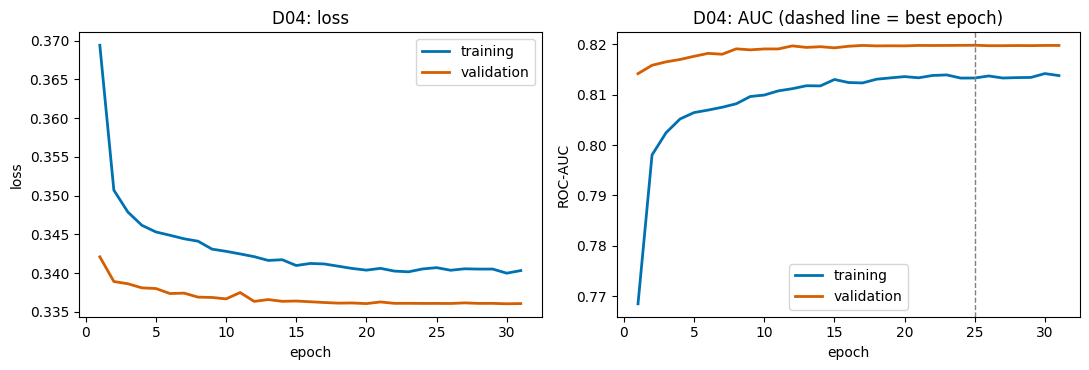

In [54]:
best_network_id = max(network_results, key=lambda experiment_id: network_results[experiment_id]["metrics"]["roc_auc"])
best_network = network_results[best_network_id]
print(f"Best neural network: {best_network_id} - {best_network['name']}")
print({metric: round(float(value), 4) for metric, value in best_network["metrics"].items()})
almost_as_good = {experiment_id: round(float(result["metrics"]["roc_auc"]), 4) for experiment_id, result in network_results.items()
                  if experiment_id != best_network_id and result["metrics"]["roc_auc"] > best_network["metrics"]["roc_auc"] - 0.001}
print("Networks within 0.001 AUC of the best one:", almost_as_good if almost_as_good else "none")
plot_learning_curves(best_network_id)

In [55]:
# All deep learning experiments, sorted by validation ROC-AUC
experiment_table = experiment_tracker.read()
network_table = experiment_table[experiment_table["step"] == "5 deep learning"]
network_table = network_table[["exp_id", "model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_seconds"]]
network_table.sort_values("roc_auc", ascending=False).reset_index(drop=True)

,exp_id,model,accuracy,precision,recall,f1,roc_auc,pr_auc,train_seconds
0,D04,Neural net 64-32 + dropout 0.3,0.8544,0.6250,0.1206,0.2022,0.8199,0.4440,37.2
1,D01,Neural net 64-32,0.8556,0.6060,0.1601,0.2533,0.8196,0.4430,14.8
2,D07,Neural net 64-32 + rmsprop,0.8553,0.5853,0.1850,0.2812,0.8195,0.4454,13.7
3,D10,Neural net 64-32 + class weights,0.7069,0.3169,0.7935,0.4530,0.8195,0.4406,17.2
4,D11,Neural net 64-32 + dropout 0.3 + class weights,0.6981,0.3122,0.8093,0.4506,0.8195,0.4432,36.5
5,D08,Neural net 64-32 + lr 0.01,0.8552,0.5907,0.1738,0.2686,0.8193,0.4399,16.5
6,D03,Neural net 32,0.8549,0.5972,0.1563,0.2478,0.8191,0.4412,25.7
7,D06,Neural net 64-32 + sgd + lr 0.01,0.8542,0.5720,0.1848,0.2794,0.8191,0.4406,26.3
8,D02,Neural net 128-64-32,0.8539,0.5746,0.1727,0.2656,0.8190,0.4393,20.8
9,D09,Neural net 64-32 + lr 0.0001,0.8544,0.5863,0.1620,0.2539,0.8189,0.4409,41.4


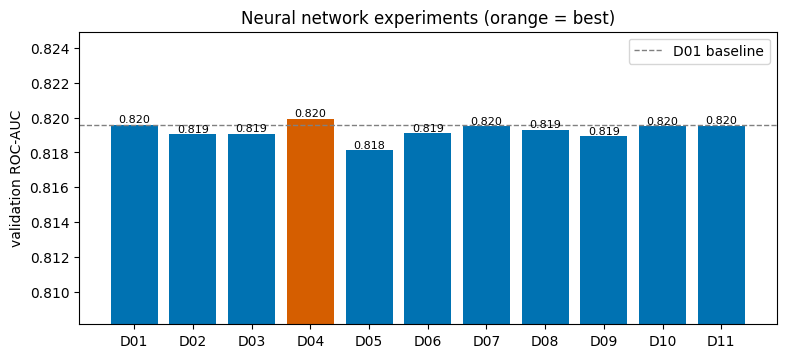

In [56]:
# Bar chart: the validation ROC-AUC of every network (the dashed line is the baseline D01)
experiment_ids = list(network_results)
auc_values = [network_results[experiment_id]["metrics"]["roc_auc"] for experiment_id in experiment_ids]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(experiment_ids, auc_values, color=[ORANGE if experiment_id == best_network_id else BLUE for experiment_id in experiment_ids])
ax.axhline(network_results["D01"]["metrics"]["roc_auc"], color="grey", ls="--", lw=1, label="D01 baseline")
ax.set_ylim(min(auc_values) - 0.01, max(auc_values) + 0.005)
ax.set_ylabel("validation ROC-AUC"); ax.set_title("Neural network experiments (orange = best)"); ax.legend()
for experiment_id, auc_value in zip(experiment_ids, auc_values):
    ax.text(experiment_id, auc_value, f"{auc_value:.3f}", ha="center", va="bottom", fontsize=8)
save_and_show("dl_experiment_comparison")

## 10. Save and reload the best neural network
Two files are saved: the whole model (`.keras`, with the architecture and the weights) and the weights alone (`.weights.h5`). Both go in the Google Drive folder. Then I reload the model and check that it makes the same predictions.

In [57]:
best_network["model"].save(MODELS_DIR / "best_deep_learning_model.keras")
best_network["model"].save_weights(MODELS_DIR / "best_deep_learning_model.weights.h5")

reloaded_network = keras.models.load_model(MODELS_DIR / "best_deep_learning_model.keras")
reloaded_network_scores = reloaded_network.predict(val_dataset, verbose=0).ravel()
print("Largest difference in the predictions after reloading:", float(np.abs(reloaded_network_scores - best_network["scores"]).max()))
print("Saved files:", sorted(file.name for file in MODELS_DIR.glob("best_*")))

Largest difference in the predictions after reloading: 0.0
Saved files: ['best_deep_learning_model.keras', 'best_deep_learning_model.weights.h5', 'best_traditional_model.joblib']


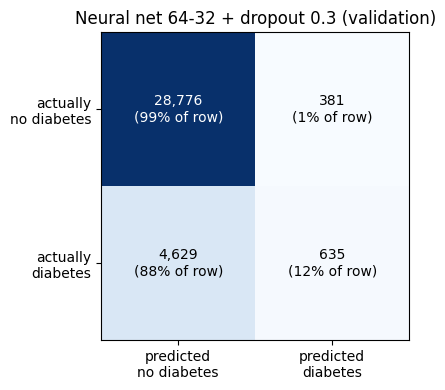

In [58]:
# Confusion matrix of the best neural network on the validation set (cut-off 0.5)
network_predictions = (best_network["scores"] >= 0.5).astype(int)
confusion = confusion_matrix(y_val, network_predictions)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(confusion, cmap="Blues"); ax.grid(False)
for row in range(2):
    for column in range(2):
        ax.text(column, row, f"{confusion[row, column]:,}\n({confusion[row, column] / confusion[row].sum():.0%} of row)",
                ha="center", va="center", color="white" if confusion[row, column] > confusion.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["predicted\nno diabetes", "predicted\ndiabetes"]); ax.set_yticklabels(["actually\nno diabetes", "actually\ndiabetes"])
ax.set_title(f"{best_network['name']} (validation)")
save_and_show("dl_confusion_matrix_best")

## 11. Traditional machine learning against deep learning (validation set)
The best model of each kind, and the simple linear model as a reference. This is a first comparison. The final comparison on the test set comes in Step 7.

In [59]:
comparison = pd.DataFrame({
    "Logistic regression (T06)": traditional_results["T06"]["metrics"],
    f"Best traditional: {best_traditional['name']} ({best_traditional_id})": best_traditional["metrics"],
    f"Best deep learning: {best_network['name']} ({best_network_id})": best_network["metrics"],
}).T.round(4)
seconds_by_experiment = experiment_tracker.read().set_index("exp_id")["train_seconds"]
comparison["train_seconds"] = [seconds_by_experiment[experiment_id] for experiment_id in ["T06", best_traditional_id, best_network_id]]
comparison

,accuracy,precision,recall,f1,roc_auc,pr_auc,train_seconds
Logistic regression (T06),0.7189,0.3231,0.7656,0.4544,0.8149,0.4305,0.4
Best traditional: Gradient boosting (tuned) (T08),0.7083,0.3179,0.7920,0.4536,0.8199,0.4457,3.4
Best deep learning: Neural net 64-32 + dropout 0.3 (D04),0.8544,0.6250,0.1206,0.2022,0.8199,0.4440,37.2


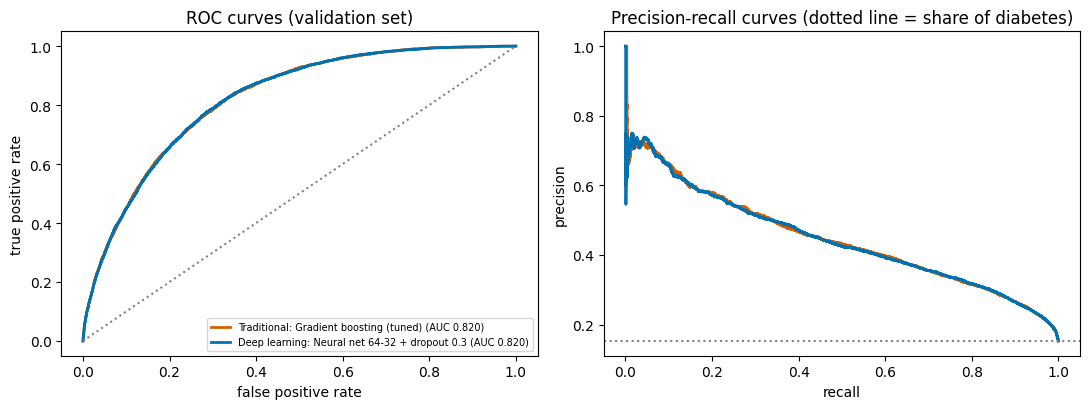

In [60]:
# ROC curve and precision-recall curve: the best traditional model against the best neural network
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for curve_label, scores, color in [(f"Traditional: {best_traditional['name']}", best_traditional["scores"], ORANGE),
                                   (f"Deep learning: {best_network['name']}", best_network["scores"], BLUE)]:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_val, scores)
    precision_values, recall_values, _ = precision_recall_curve(y_val, scores)
    axes[0].plot(false_positive_rate, true_positive_rate, color=color, lw=2, label=f"{curve_label} (AUC {roc_auc_score(y_val, scores):.3f})")
    axes[1].plot(recall_values, precision_values, color=color, lw=2)
axes[0].plot([0, 1], [0, 1], ":", color="grey"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curves (validation set)"); axes[0].legend(fontsize=7, loc="lower right")
axes[1].axhline(y_val.mean(), color="grey", ls=":"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves (dotted line = share of diabetes)")
plt.tight_layout()
save_and_show("dl_vs_ml_curves")

## 12. Observations for the experiment table
A short note for each run, written into `reports/experiment_log.csv`. The numbers are filled in by the code from the results above. In the report I put the notes in my own words and add the reasons.

In [61]:
def metric_of(experiment_id, metric_name):
    return network_results[experiment_id]["metrics"][metric_name]


def setting_of(experiment_id, setting_name):
    return network_results[experiment_id]["settings"][setting_name]


def train_validation_gap(experiment_id):
    # The training AUC minus the validation AUC at the best epoch.
    history_values = network_results[experiment_id]["history"]
    best_index = setting_of(experiment_id, "best_epoch") - 1
    return history_values["auc"][best_index] - history_values["val_auc"][best_index]


network_observations = {
    "D01": f"Baseline. Validation ROC-AUC {metric_of('D01', 'roc_auc'):.4f}, best epoch {setting_of('D01', 'best_epoch')} of {setting_of('D01', 'epochs_run')}. Without class weights the recall at the 0.5 cut-off is only {metric_of('D01', 'recall'):.2f} (precision {metric_of('D01', 'precision'):.2f}).",
    "D02": f"Wider and deeper: ROC-AUC {metric_of('D02', 'roc_auc'):.4f} ({metric_of('D02', 'roc_auc') - metric_of('D01', 'roc_auc'):+.4f} against D01) with {setting_of('D02', 'epochs_run')} epochs. The training AUC is {train_validation_gap('D02'):+.3f} above the validation AUC at the best epoch. That is the largest gap of all runs and a hint of overfitting, but there is no gain.",
    "D03": f"One hidden layer of 32: ROC-AUC {metric_of('D03', 'roc_auc'):.4f} ({metric_of('D03', 'roc_auc') - metric_of('D01', 'roc_auc'):+.4f} against D01). A much smaller network scores about the same, so the size of the network is not what limits the result. It needed {setting_of('D03', 'best_epoch')} epochs to reach its best.",
    "D04": f"Dropout 0.3: ROC-AUC {metric_of('D04', 'roc_auc'):.4f} ({metric_of('D04', 'roc_auc') - metric_of('D01', 'roc_auc'):+.4f} against D01, inside the noise). Training is slower (best epoch {setting_of('D04', 'best_epoch')}) and the recall at the 0.5 cut-off drops to {metric_of('D04', 'recall'):.2f}.",
    "D05": f"Batch normalization: ROC-AUC {metric_of('D05', 'roc_auc'):.4f} ({metric_of('D05', 'roc_auc') - metric_of('D01', 'roc_auc'):+.4f} against D01). Training stopped after {setting_of('D05', 'epochs_run')} epochs. No benefit for this small network.",
    "D06": f"SGD with momentum (learning rate 0.01): ROC-AUC {metric_of('D06', 'roc_auc'):.4f}. It needed {setting_of('D06', 'best_epoch')} epochs to reach its best, against {setting_of('D01', 'best_epoch')} for Adam. It converges more slowly for the same quality.",
    "D07": f"RMSprop: ROC-AUC {metric_of('D07', 'roc_auc'):.4f}, PR-AUC {metric_of('D07', 'pr_auc'):.4f}. Very close to Adam (D01).",
    "D08": f"Adam with a 10 times bigger learning rate (0.01): ROC-AUC {metric_of('D08', 'roc_auc'):.4f}. Training did not become unstable here. (ReduceLROnPlateau can halve the rate when progress stalls, which may hide an unstable start.)",
    "D09": f"Adam with a 10 times smaller learning rate (0.0001): ROC-AUC {metric_of('D09', 'roc_auc'):.4f}. The best epoch is {setting_of('D09', 'best_epoch')} of {setting_of('D09', 'epochs_run')} (the limit is {MAX_EPOCHS}), so it was still improving when it stopped and is probably not fully trained.",
    "D10": f"Class weights: ROC-AUC {metric_of('D10', 'roc_auc'):.4f} (the same ranking quality as D01), but recall {metric_of('D10', 'recall'):.2f} against {metric_of('D01', 'recall'):.2f}, precision {metric_of('D10', 'precision'):.2f} against {metric_of('D01', 'precision'):.2f} and accuracy {metric_of('D10', 'accuracy'):.3f}. Class weights change the balance of the errors, not how well the people are ranked.",
    "D11": f"Dropout 0.3 and class weights: ROC-AUC {metric_of('D11', 'roc_auc'):.4f}, recall {metric_of('D11', 'recall'):.2f}, precision {metric_of('D11', 'precision'):.2f}. Compare with D04 (dropout only) and D10 (class weights only).",
}
experiment_tracker.set_observations(network_observations)
network_overview = experiment_tracker.read()
network_overview[network_overview["step"] == "5 deep learning"][["exp_id", "model", "roc_auc", "observations"]]

,exp_id,model,roc_auc,observations
0,D01,Neural net 64-32,0.8196,"Baseline. Validation ROC-AUC 0.8196, best epoc..."
1,D02,Neural net 128-64-32,0.8190,Wider and deeper: ROC-AUC 0.8190 (-0.0006 agai...
2,D03,Neural net 32,0.8191,One hidden layer of 32: ROC-AUC 0.8191 (-0.000...
3,D04,Neural net 64-32 + dropout 0.3,0.8199,Dropout 0.3: ROC-AUC 0.8199 (+0.0003 against D...
4,D05,Neural net 64-32 + batch norm,0.8181,Batch normalization: ROC-AUC 0.8181 (-0.0015 a...
5,D06,Neural net 64-32 + sgd + lr 0.01,0.8191,SGD with momentum (learning rate 0.01): ROC-AU...
6,D07,Neural net 64-32 + rmsprop,0.8195,"RMSprop: ROC-AUC 0.8195, PR-AUC 0.4454. Very c..."
7,D08,Neural net 64-32 + lr 0.01,0.8193,Adam with a 10 times bigger learning rate (0.0...
8,D09,Neural net 64-32 + lr 0.0001,0.8189,Adam with a 10 times smaller learning rate (0....
9,D10,Neural net 64-32 + class weights,0.8195,Class weights: ROC-AUC 0.8195 (the same rankin...


## 13. Looking at the training in TensorBoard
```
.venv/bin/tensorboard --logdir logs/tensorboard
```
Open http://localhost:6006. For each `D..` run, the Scalars tab shows the loss, AUC, precision, recall and accuracy after every epoch (training and validation as two lines). The HParams tab compares all experiments (T01 to T11 and D01 to D11) with their settings. The same numbers are in `logs/training_csv/` as CSV files. The overview of every run is in `logs/step4_traditional_ml.log`, `logs/step5_deep_learning.log` and `reports/experiment_log.csv`.

In [62]:
print("TensorBoard runs written so far:", len(list((LOGS_DIR / "tensorboard").iterdir())))
print("Epoch-by-epoch CSV logs:", len(list(CSV_LOG_DIR.glob("*.csv"))))

TensorBoard runs written so far: 28
Epoch-by-epoch CSV logs: 11


## 14. Summary of Step 5

What the output above shows:
- I trained 11 neural networks (D01 to D11). Together with the 11 scikit-learn experiments of Step 4 there are 22 logged experiments in `reports/experiment_log.csv`, and each one has a TensorBoard run.
- All 11 networks have a validation ROC-AUC between 0.818 and 0.820, so they are practically tied. The best one by my rule is D04 (dropout 0.3, AUC 0.8199), but eight other networks are within 0.001 of it, so choosing between them means little. It is saved as `models/best_deep_learning_model.keras` (and `.weights.h5`), and reloading it gives identical predictions.
- The best network (0.8199) reaches the same ROC-AUC as the tuned gradient boosting model from Step 4 (0.8199). This suggests, but does not prove, that the limit is the information in the 25 features and in the labels, and not the type of model.
- The size of the network did not matter: one layer of 32 neurons (0.8191) scored the same as 128-64-32 (0.8190).
- Overfitting is small. At the best epoch the gap between the training AUC and the validation AUC stays between -0.007 and +0.003, and only the largest network (D02) has a training AUC above its validation AUC. Early stopping chose best epochs between 6 and 40.
- Optimizers and learning rates: SGD needed about 20 epochs against 7 for Adam, and the learning rate 0.0001 was still improving at the limit of 40 epochs, so that run is probably not fully trained. Batch normalization gave the lowest AUC (0.8181).
- Class weights again changed the balance of the errors and not the ranking: the recall rose from 0.16 to 0.79 and the precision fell from 0.61 to 0.32.
- A network needs tens of seconds to train, and the tuned boosting model only a few seconds.
- The test set has not been used yet.

Questions I answer in my own words before the report:
1. Why did the size of the network, the optimizer and the learning rate change the ROC-AUC so little? How does this connect to the plateau I saw in Step 4?
2. Looking at the learning curves of D01 and D02, do I see overfitting or underfitting? Which numbers (gap, best epoch) support my answer?
3. For a screening tool, would I recommend the gradient boosting model (T08) or a neural network (D10 or D11)? Think about recall, precision, training time and how easy each one is to explain.

---
# Step 6: Experiment tracking and comparison

So far there are 22 experiments. This step makes the experiment table something that another person can trust and reproduce.

| Question | What I do |
|---|---|
| Which experiment builds on which, and what exactly changed? | Add two columns, "builds on" and "single change", so the order of the experiments tells a story |
| Are the small differences real or just noise? | Repeat the best traditional model on 5 different random splits and the baseline network with 5 different random starts, and measure how much the scores move |
| Can every number in the table be traced to a logged run? | An audit compares each value of the table with the value stored in its TensorBoard run |
| What are the trade-offs between the models? | Plots of the whole progression, of precision against recall, and of quality against training time |

The result is saved as `reports/experiment_table.csv` and `reports/experiment_table.md` (a table that can be pasted into the report).

## 1. Setup

In [63]:
import ast
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# A new tracker for this step: the same experiment table and TensorBoard folder, and its own text log.
experiment_tracker = ExperimentTracker(REPORTS_DIR / "experiment_log.csv", LOGS_DIR / "tensorboard",
                                       LOGS_DIR / "step6_comparison.log")
print("Experiments in the log before this step:", len(experiment_tracker.read()))

Experiments in the log before this step: 24


## 2. How big is the random noise?
Until now I compared the models on one train/validation split, and the networks started from one random initialisation. Many differences were about 0.001 in ROC-AUC. To know whether such a difference means anything, I measure how much the score moves when only the randomness changes.

- T12: the tuned gradient boosting model (T08) on 5 different random 70/15/15 splits (seeds 1 to 5). For each split the preprocessing is fitted again, on the training data of that split only.
- D12: the baseline network (D01) trained 5 times with different random starting weights (seeds 1 to 5), on the same split. The shuffling seed of the `tf.data` pipeline is not changed.

Each experiment is logged as one row with the mean of the 5 repeats. The spread (standard deviation) is stored in the hyperparameters column.

In [64]:
# --- T12: the same model on 5 different splits ---
start_time = time.time()
boosting_split_scores = []
for split_seed in [1, 2, 3, 4, 5]:
    split_X_train, split_X_val, _, split_y_train, split_y_val, _ = split_data(data_with_features, seed=split_seed)
    split_preprocessor = build_preprocessor(use_engineered=True).fit(split_X_train)    # fitted on this split's training data only
    split_model = clone(boosting_search.best_estimator_)
    split_model.fit(transform_to_frame(split_preprocessor, split_X_train), split_y_train)
    split_scores = split_model.predict_proba(transform_to_frame(split_preprocessor, split_X_val))[:, 1]
    boosting_split_scores.append(evaluate_binary(split_y_val.values, split_scores))
boosting_repeats = pd.DataFrame(boosting_split_scores, index=[f"split {seed}" for seed in [1, 2, 3, 4, 5]])
boosting_seconds = time.time() - start_time
boosting_repeats.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
split 1,0.7099,0.3187,0.7880,0.4538,0.8177,0.4356
split 2,0.7094,0.3167,0.7774,0.4500,0.8158,0.4405
split 3,0.7117,0.3206,0.7908,0.4563,0.8199,0.4438
split 4,0.7127,0.3210,0.7874,0.4560,0.8164,0.4294
split 5,0.7107,0.3192,0.7872,0.4543,0.8190,0.4393


In [65]:
# --- D12: the same network with 5 different random starting weights ---
def train_network_with_seed(weight_seed):
    keras.utils.set_random_seed(weight_seed)                # this changes the starting weights
    network = build_model(train_scaled.shape[1], (64, 32))
    network.compile(optimizer=make_optimizer("adam", 0.001), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    stop_early = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True)
    network.fit(train_dataset, validation_data=val_dataset, epochs=MAX_EPOCHS, verbose=0, shuffle=False, callbacks=[stop_early])
    return evaluate_binary(y_val.values, network.predict(val_dataset, verbose=0).ravel())


start_time = time.time()
network_repeats = pd.DataFrame([train_network_with_seed(seed) for seed in [1, 2, 3, 4, 5]],
                               index=[f"seed {seed}" for seed in [1, 2, 3, 4, 5]])
network_seconds = time.time() - start_time
network_repeats.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
seed 1,0.8550,0.5739,0.2014,0.2981,0.8186,0.4410
seed 2,0.8546,0.5660,0.2109,0.3073,0.8189,0.4409
seed 3,0.8540,0.5730,0.1782,0.2718,0.8190,0.4418
seed 4,0.8546,0.5694,0.2027,0.2990,0.8202,0.4414
seed 5,0.8550,0.5744,0.2010,0.2978,0.8194,0.4412


In [66]:
# The mean and the standard deviation of the 5 repeats, and a record of both experiments.
boosting_mean, boosting_std = boosting_repeats.mean(), boosting_repeats.std(ddof=1)
network_mean, network_std = network_repeats.mean(), network_repeats.std(ddof=1)

experiment_tracker.log_experiment("T12", "6 repeatability", "Gradient boosting (tuned), mean of 5 splits",
                                  {**boosting_search.best_params_, "class_weight": "balanced", "split_seeds": "1-5",
                                   "roc_auc_std": round(boosting_std["roc_auc"], 4)},
                                  ALL_FEATURES_DESCRIPTION, "5 random stratified 70/15/15 splits (seeds 1 to 5), duplicates removed",
                                  "validation (mean of 5 splits)", boosting_mean.to_dict(), boosting_seconds / 5)
experiment_tracker.log_experiment("D12", "6 repeatability", "Neural net 64-32, mean of 5 random starts",
                                  {"hidden_layers": "64-32", "optimizer": "adam", "learning_rate": 0.001, "weight_seeds": "1-5",
                                   "roc_auc_std": round(network_std["roc_auc"], 4)},
                                  ALL_FEATURES_DESCRIPTION, SPLIT_DESCRIPTION, "validation (mean of 5 random starts)",
                                  network_mean.to_dict(), network_seconds / 5)

repeat_summary = pd.DataFrame({"boosting, 5 splits (mean)": boosting_mean, "boosting (std)": boosting_std,
                               "network, 5 starts (mean)": network_mean, "network (std)": network_std}).round(4)
repeat_summary

19:06:01 | T12 | Gradient boosting (tuned), mean of 5 splits | acc 0.711 | precision 0.319 | recall 0.786 | F1 0.454 | ROC-AUC 0.818 | PR-AUC 0.438 | 4.7s


19:06:01 | D12 | Neural net 64-32, mean of 5 random starts | acc 0.855 | precision 0.571 | recall 0.199 | F1 0.295 | ROC-AUC 0.819 | PR-AUC 0.441 | 11.8s


,"boosting, 5 splits (mean)",boosting (std),"network, 5 starts (mean)",network (std)
accuracy,0.7109,0.0013,0.8547,0.0004
precision,0.3192,0.0017,0.5713,0.0036
recall,0.7862,0.0051,0.1988,0.0122
f1,0.4541,0.0025,0.2948,0.0134
roc_auc,0.8178,0.0017,0.8192,0.0006
pr_auc,0.4377,0.0055,0.4413,0.0003


How to read the spread: the standard deviation of the ROC-AUC over the repeats is the size of a difference that I cannot tell apart from luck. Differences between experiments that are smaller than about two standard deviations should not be reported as improvements. I use this rule when I discuss the earlier experiments.

## 3. The complete experiment table
I add the two columns "builds on" and "single change". I write them by hand from the experiment plans of Steps 4 and 5. The code that ran each experiment is in the sections of those steps.

In [67]:
# experiment -> (the experiment it builds on, the single change compared with it)
lineage = {
    "T01": ("-", "Baseline: always predict 'no diabetes'"),
    "T02": ("T01", "First real model: logistic regression with class weights"),
    "T03": ("T02", "Different model family: random forest"),
    "T04": ("T03", "Different model family: gradient boosting"),
    "T05": ("T04", "Different model family: SVM (20,000-row training sample)"),
    "T06": ("T02", "Tune C and the class weighting (grid search, 3-fold CV)"),
    "T07": ("T03", "Tune depth, leaf size and max_features (random search, 3-fold CV)"),
    "T08": ("T04", "Tune learning rate, leaves, leaf size and L2 (random search, 3-fold CV)"),
    "T09": ("T08", "Remove the 4 engineered features"),
    "T10": ("T08", "Remove the class weights"),
    "T11": ("T08", "SMOTE on the training set instead of class weights"),
    "D01": ("T08 (same data)", "First neural network: layers 64-32, Adam 0.001"),
    "D02": ("D01", "Wider and deeper: 128-64-32"),
    "D03": ("D01", "Smaller: one layer of 32"),
    "D04": ("D01", "Dropout 0.3"),
    "D05": ("D01", "Batch normalization"),
    "D06": ("D01", "Optimizer SGD with momentum, learning rate 0.01"),
    "D07": ("D01", "Optimizer RMSprop"),
    "D08": ("D01", "Learning rate 0.01"),
    "D09": ("D01", "Learning rate 0.0001"),
    "D10": ("D01", "Class weights"),
    "D11": ("D04 + D10", "Dropout 0.3 and class weights together"),
    "T12": ("T08", "Repeat on 5 random splits (measures the noise)"),
    "D12": ("D01", "Repeat with 5 random starts (measures the noise)"),
}

experiment_table = experiment_tracker.read()
experiment_table["builds_on"] = experiment_table["exp_id"].map(lambda experiment_id: lineage[experiment_id][0])
experiment_table["single_change"] = experiment_table["exp_id"].map(lambda experiment_id: lineage[experiment_id][1])

full_columns = ["exp_id", "model", "builds_on", "single_change", "hyperparameters", "features", "split", "eval_set",
                "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_seconds", "observations"]
full_table = experiment_table[full_columns]
full_table.to_csv(REPORTS_DIR / "experiment_table.csv", index=False)


def write_markdown_table(table, file_path):
    # Write a DataFrame as a markdown table. Pipes and line breaks are removed from the text so the table stays intact.
    lines = ["| " + " | ".join(table.columns) + " |", "|" + "|".join(["---"] * len(table.columns)) + "|"]
    for _, row in table.iterrows():
        cells = [str(value).replace("|", "/").replace("\n", " ") for value in row]
        lines.append("| " + " | ".join(cells) + " |")
    Path(file_path).write_text("\n".join(lines) + "\n")


write_markdown_table(full_table, REPORTS_DIR / "experiment_table.md")
print("Saved reports/experiment_table.csv and reports/experiment_table.md with", len(full_table), "experiments")

# A compact view: this is the kind of table to put in the report.
compact_table = experiment_table[["exp_id", "model", "builds_on", "single_change", "roc_auc", "pr_auc", "f1", "recall", "precision", "train_seconds"]]
compact_table

Saved reports/experiment_table.csv and reports/experiment_table.md with 24 experiments


,exp_id,model,builds_on,single_change,roc_auc,pr_auc,f1,recall,precision,train_seconds
0,D01,Neural net 64-32,T08 (same data),"First neural network: layers 64-32, Adam 0.001",0.8196,0.4430,0.2533,0.1601,0.6060,14.8
1,D02,Neural net 128-64-32,D01,Wider and deeper: 128-64-32,0.8190,0.4393,0.2656,0.1727,0.5746,20.8
2,D03,Neural net 32,D01,Smaller: one layer of 32,0.8191,0.4412,0.2478,0.1563,0.5972,25.7
3,D04,Neural net 64-32 + dropout 0.3,D01,Dropout 0.3,0.8199,0.4440,0.2022,0.1206,0.6250,37.2
4,D05,Neural net 64-32 + batch norm,D01,Batch normalization,0.8181,0.4397,0.2804,0.1858,0.5716,15.6
5,D06,Neural net 64-32 + sgd + lr 0.01,D01,"Optimizer SGD with momentum, learning rate 0.01",0.8191,0.4406,0.2794,0.1848,0.5720,26.3
6,D07,Neural net 64-32 + rmsprop,D01,Optimizer RMSprop,0.8195,0.4454,0.2812,0.1850,0.5853,13.7
7,D08,Neural net 64-32 + lr 0.01,D01,Learning rate 0.01,0.8193,0.4399,0.2686,0.1738,0.5907,16.5
8,D09,Neural net 64-32 + lr 0.0001,D01,Learning rate 0.0001,0.8189,0.4409,0.2539,0.1620,0.5863,41.4
9,D10,Neural net 64-32 + class weights,D01,Class weights,0.8195,0.4406,0.4530,0.7935,0.3169,17.2


## 4. Audit: can every number be traced to a logged run?
For every experiment I read the ROC-AUC stored in its TensorBoard run and compare it with the table. For the networks I also check that the CSV log of the epochs has as many rows as the number of epochs in the table. If anything does not match, the cell stops with an error.

In [68]:
def read_tensorboard_value(run_name, metric_tag):
    # The last value of a metric in the TensorBoard folder of a run (None if the run or the metric is missing).
    run_folder = LOGS_DIR / "tensorboard" / run_name
    if not run_folder.exists():
        return None
    reader = EventAccumulator(str(run_folder), size_guidance={"tensors": 0})
    reader.Reload()
    if metric_tag not in reader.Tags()["tensors"]:
        return None
    return float(tf.make_ndarray(reader.Tensors(metric_tag)[-1].tensor_proto))


audit_rows = []
for _, row in experiment_table.iterrows():
    run_name = ExperimentTracker.run_name(row["exp_id"], row["model"])
    tensorboard_auc = read_tensorboard_value(run_name, "roc_auc")
    epochs_in_table, epochs_in_csv_log = "-", "-"
    if row["step"] == "5 deep learning":
        epochs_in_table = ast.literal_eval(row["hyperparameters"])["epochs_run"]
        epochs_in_csv_log = len(pd.read_csv(LOGS_DIR / "training_csv" / f"{row['exp_id']}.csv"))
    audit_rows.append({"experiment": row["exp_id"], "table ROC-AUC": row["roc_auc"],
                       "TensorBoard ROC-AUC": None if tensorboard_auc is None else round(tensorboard_auc, 4),
                       "same value": tensorboard_auc is not None and abs(tensorboard_auc - row["roc_auc"]) < 1e-4,
                       "epochs (table)": epochs_in_table, "epochs (CSV log)": epochs_in_csv_log})
audit = pd.DataFrame(audit_rows).set_index("experiment")
assert audit["same value"].all(), "some values in the table do not match their TensorBoard run"
network_audit = audit[audit["epochs (table)"] != "-"]
assert (network_audit["epochs (table)"] == network_audit["epochs (CSV log)"]).all(), "the epoch counts differ"
print(f"All {len(audit)} experiments match their TensorBoard run, and the epoch counts of all {len(network_audit)} networks match their CSV logs.")
audit

All 24 experiments match their TensorBoard run, and the epoch counts of all 11 networks match their CSV logs.


,table ROC-AUC,TensorBoard ROC-AUC,same value,epochs (table),epochs (CSV log)
experiment,,,,,
D01,0.8196,0.8196,True,13,13
D02,0.8190,0.8190,True,16,16
D03,0.8191,0.8191,True,28,28
D04,0.8199,0.8199,True,31,31
D05,0.8181,0.8181,True,12,12
D06,0.8191,0.8191,True,26,26
D07,0.8195,0.8195,True,13,13
D08,0.8193,0.8193,True,16,16
D09,0.8189,0.8189,True,40,40


## 5. The whole progression and the trade-offs
### 5.1 Does anything get past the plateau?
The ROC-AUC of every trained model, in the order in which the experiments were run. The grey band is the noise measured in section 2: the mean of T12 plus or minus two standard deviations.

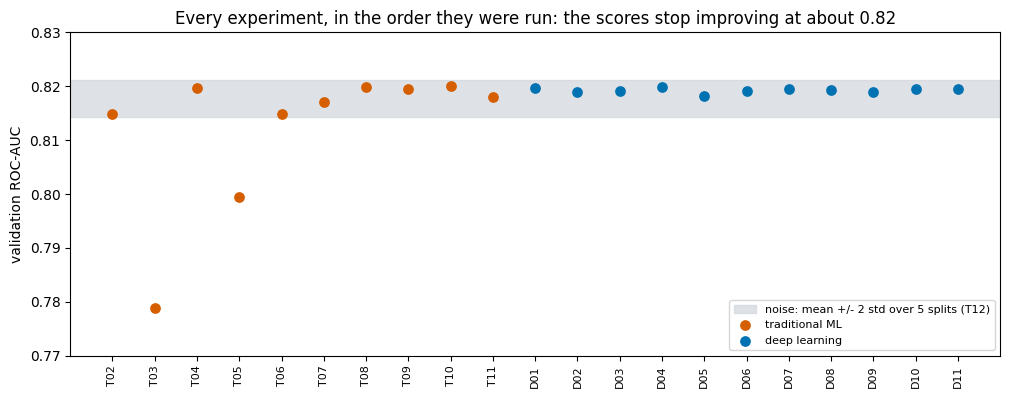

Best ROC-AUC: 0.8200 | models within 0.002 of the best: 16 of 21
Noise (2 std) over 5 splits: 0.0034 | over 5 random starts of the network: 0.0012


In [69]:
trained_experiments = experiment_table[experiment_table["exp_id"] != "T01"].copy()                  # the dummy model (AUC 0.5) is not shown
trained_experiments = trained_experiments[~trained_experiments["exp_id"].isin(["T12", "D12"])]      # the repeat runs are shown as the band
# The order in which the experiments were run: T01-T11 first (Step 4), then D01-D11 (Step 5).
trained_experiments = trained_experiments.sort_values(["step", "exp_id"]).reset_index(drop=True)
trained_experiments["family"] = np.where(trained_experiments["exp_id"].str.startswith("T"), "traditional ML", "deep learning")

fig, ax = plt.subplots(figsize=(12, 4.2))
positions = np.arange(len(trained_experiments))
ax.axhspan(boosting_mean["roc_auc"] - 2 * boosting_std["roc_auc"], boosting_mean["roc_auc"] + 2 * boosting_std["roc_auc"],
           color="#d1d5db", alpha=0.7, label="noise: mean +/- 2 std over 5 splits (T12)")
for family, color in [("traditional ML", ORANGE), ("deep learning", BLUE)]:
    family_rows = trained_experiments[trained_experiments["family"] == family]
    ax.scatter(positions[family_rows.index], family_rows["roc_auc"], color=color, s=45, label=family, zorder=3)
ax.set_xticks(positions); ax.set_xticklabels(trained_experiments["exp_id"], rotation=90, fontsize=8)
ax.set_ylabel("validation ROC-AUC"); ax.set_ylim(0.77, 0.83)
ax.set_title("Every experiment, in the order they were run: the scores stop improving at about 0.82")
ax.legend(loc="lower right", fontsize=8)
save_and_show("cmp01_progression")

best_auc = trained_experiments["roc_auc"].max()
print(f"Best ROC-AUC: {best_auc:.4f} | models within 0.002 of the best: "
      f"{(trained_experiments['roc_auc'] >= best_auc - 0.002).sum()} of {len(trained_experiments)}")
print(f"Noise (2 std) over 5 splits: {2 * boosting_std['roc_auc']:.4f} | over 5 random starts of the network: {2 * network_std['roc_auc']:.4f}")

### 5.2 Precision against recall: what the handling of the imbalance changes
Each point is one experiment, evaluated at the 0.5 cut-off. Models trained with class weights or SMOTE sit in a different place than models trained without any help, even though their ROC-AUC is about the same.

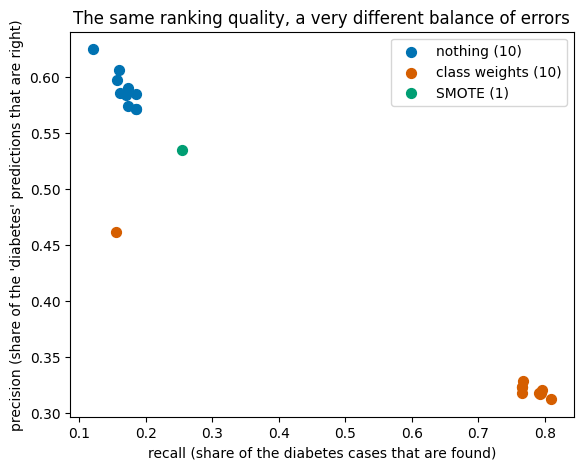

               roc_auc  recall  precision  accuracy
imbalance                                          
SMOTE            0.818   0.255      0.535     0.852
class weights    0.812   0.721      0.334     0.725
nothing          0.819   0.167      0.589     0.855


In [70]:
def imbalance_method_of(experiment_row):
    # How was the class imbalance handled in this experiment?
    if "SMOTE" in experiment_row["features"]:
        return "SMOTE"
    if "balanced" in experiment_row["hyperparameters"] or "'class_weights': True" in experiment_row["hyperparameters"]:
        return "class weights"
    return "nothing"


trained_experiments["imbalance"] = trained_experiments.apply(imbalance_method_of, axis=1)
method_colors = {"nothing": BLUE, "class weights": ORANGE, "SMOTE": "#009E73"}

fig, ax = plt.subplots(figsize=(6.5, 5))
for method, color in method_colors.items():
    method_rows = trained_experiments[trained_experiments["imbalance"] == method]
    ax.scatter(method_rows["recall"], method_rows["precision"], color=color, s=50, label=f"{method} ({len(method_rows)})", zorder=3)
ax.set_xlabel("recall (share of the diabetes cases that are found)")
ax.set_ylabel("precision (share of the 'diabetes' predictions that are right)")
ax.set_title("The same ranking quality, a very different balance of errors"); ax.legend()
save_and_show("cmp02_precision_recall_tradeoff")
print(trained_experiments.groupby("imbalance")[["roc_auc", "recall", "precision", "accuracy"]].mean().round(3))

### 5.3 Cost against quality
The training time (log scale) against the ROC-AUC. When the scores are tied, the model that is cheapest to train is the one to prefer.

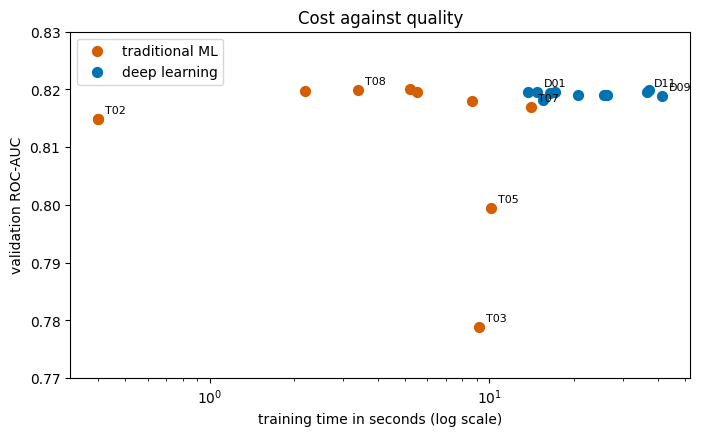

,exp_id,model,roc_auc,train_seconds
0,T02,Logistic regression,0.8149,0.4
4,T06,Logistic regression (tuned),0.8149,0.4
2,T04,Gradient boosting,0.8197,2.2
6,T08,Gradient boosting (tuned),0.8199,3.4
8,T10,"Gradient boosting (tuned), no class weights",0.8200,5.2


In [71]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for family, color in [("traditional ML", ORANGE), ("deep learning", BLUE)]:
    family_rows = trained_experiments[trained_experiments["family"] == family]
    ax.scatter(family_rows["train_seconds"].clip(lower=0.1), family_rows["roc_auc"], color=color, s=50, label=family, zorder=3)
for _, row in trained_experiments[trained_experiments["exp_id"].isin(["T02", "T03", "T05", "T07", "T08", "D01", "D09", "D11"])].iterrows():
    ax.annotate(row["exp_id"], (max(row["train_seconds"], 0.1), row["roc_auc"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("training time in seconds (log scale)"); ax.set_ylabel("validation ROC-AUC")
ax.set_ylim(0.77, 0.83); ax.set_title("Cost against quality"); ax.legend()
save_and_show("cmp03_cost_vs_quality")
trained_experiments[["exp_id", "model", "roc_auc", "train_seconds"]].sort_values("train_seconds").head(5)

## 6. Observations for the repeat experiments

In [72]:
repeat_observations = {
    "T12": f"The same model on 5 random splits: ROC-AUC {boosting_mean['roc_auc']:.4f} +/- {boosting_std['roc_auc']:.4f} (std), range {boosting_repeats['roc_auc'].min():.4f} to {boosting_repeats['roc_auc'].max():.4f}. Differences below about {2 * boosting_std['roc_auc']:.4f} between experiments are inside the split noise.",
    "D12": f"The same network with 5 random starts: ROC-AUC {network_mean['roc_auc']:.4f} +/- {network_std['roc_auc']:.4f} (std), range {network_repeats['roc_auc'].min():.4f} to {network_repeats['roc_auc'].max():.4f}. The noise from the starting weights alone is about {2 * network_std['roc_auc']:.4f} (2 std).",
}
experiment_tracker.set_observations(repeat_observations)

# The saved tables are written again, so that they include these last two observations.
experiment_table = experiment_tracker.read()
experiment_table["builds_on"] = experiment_table["exp_id"].map(lambda experiment_id: lineage[experiment_id][0])
experiment_table["single_change"] = experiment_table["exp_id"].map(lambda experiment_id: lineage[experiment_id][1])
full_table = experiment_table[full_columns]
full_table.to_csv(REPORTS_DIR / "experiment_table.csv", index=False)
write_markdown_table(full_table, REPORTS_DIR / "experiment_table.md")
full_table[full_table["exp_id"].isin(["T12", "D12"])][["exp_id", "model", "roc_auc", "observations"]]

,exp_id,model,roc_auc,observations
11,D12,"Neural net 64-32, mean of 5 random starts",0.8192,The same network with 5 random starts: ROC-AUC...
23,T12,"Gradient boosting (tuned), mean of 5 splits",0.8178,The same model on 5 random splits: ROC-AUC 0.8...


## 7. Files of this step
- `reports/experiment_table.csv` and `reports/experiment_table.md`: the complete experiment table (24 rows, with settings, split, metrics, time, what each experiment builds on, and a note).
- `reports/experiment_log.csv`: the raw log written by the tracker while the experiments ran.
- `logs/tensorboard/`: one run per experiment (view with `.venv/bin/tensorboard --logdir logs/tensorboard`).
- `logs/*.log` and `logs/training_csv/`: text logs and epoch-by-epoch logs.
- `images/cmp01` to `images/cmp03`: the comparison figures.

In [73]:
print("Rows in experiment_table.csv:", len(pd.read_csv(REPORTS_DIR / "experiment_table.csv")))
print("TensorBoard runs:", len(list((LOGS_DIR / "tensorboard").iterdir())))

Rows in experiment_table.csv: 24
TensorBoard runs: 28


## 8. Summary of Step 6

What the output above shows:
- The complete experiment table has 24 experiments: 11 traditional (T01 to T11), 11 deep learning (D01 to D11) and 2 repeat experiments (T12 and D12). It is saved in `reports/experiment_table.csv` and `reports/experiment_table.md`, with the settings, the split, the metrics, the training time, the experiment that each one builds on, the single change, and a note.
- The audit passed: all 24 values match their TensorBoard run, and the epoch counts of all 11 networks match their CSV logs.
- Noise: the tuned gradient boosting model scores a ROC-AUC of 0.8178 +/- 0.0017 over 5 random splits (range 0.8158 to 0.8199). The baseline network scores 0.8192 +/- 0.0006 over 5 random starts (range 0.8186 to 0.8202). Two standard deviations are 0.0034 and 0.0012.
- The plateau: 16 of the 21 trained models are within 0.002 of the best ROC-AUC (0.8200).
- Differences that are larger than the noise: the untuned random forest (0.7788), the SVM on a sample (0.7995) and logistic regression (0.8149, about 0.005 below the best).
- Differences that are inside the noise: tuned boosting against the tuned forest (0.0029), the engineered features (0.0004), dropout (0.0003) and the choice of the optimizer. Batch normalization (-0.0015 against D01) is only slightly outside the noise of the random starts, so it may be a small real effect.
- Class imbalance: models trained with class weights find on average 72% of the diabetes cases with a precision of 0.33. Models without any help find 17% with a precision of 0.59. The single SMOTE run finds 26% with a precision of 0.54. The ranking quality (ROC-AUC) is about the same.
- Cost: logistic regression trains in under a second (AUC 0.8149), the tuned boosting model in a few seconds (0.8199), and a network in tens of seconds (about 0.819).
- A caution: the noise was measured for two models only, and by changing the split. Comparisons on one fixed split are paired, so the real noise for them may be smaller. The test set has not been used yet.

Questions I answer in my own words before the report:
1. Using the noise measured here, which differences between my experiments are real and which are not? Give two examples of each.
2. Why do class weights change the precision and the recall but not the ROC-AUC?
3. Looking at the plot of cost against quality, which model would I choose to use, and why?

---
# Step 7: Error analysis on the test set

The rule for the test set: I chose the two models with the validation set only. They are the tuned gradient boosting model (T08) and the neural network D04, picked by the fixed rules of Steps 4 and 5. Now I use the test set for the first time, and only for these two models, so the result is an honest estimate of how they behave on new people. Anything I tune here (the decision cut-offs) is tuned on the validation set and then applied to the test set.

| Question | Section |
|---|---|
| How good are the two models on new data, and is the score stable? | 2, 3 |
| What kinds of mistakes do they make? (confusion matrices) | 4 |
| What is the trade-off between finding cases and raising false alarms? (ROC, precision-recall, cut-offs) | 5, 6 |
| Can the predicted scores be trusted as risks? (calibration) | 7 |
| Is the limit caused by bias or by variance? (training against validation) | 8 |
| Who does the model get wrong? (subgroups and the profile of the mistakes) | 9, 10 |
| What would I try next? | 11 |

## 1. Load the two saved models and score the test set

In [74]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, average_precision_score, f1_score, precision_score, recall_score

experiment_tracker = ExperimentTracker(REPORTS_DIR / "experiment_log.csv", LOGS_DIR / "tensorboard",
                                       LOGS_DIR / "step7_error_analysis.log")

# I load the models from the saved files. This also proves that the saved files work.
traditional_pipeline = joblib.load(MODELS_DIR / "best_traditional_model.joblib")       # takes the raw answer columns
network_model = keras.models.load_model(MODELS_DIR / "best_deep_learning_model.keras")  # takes the scaled features

traditional_name = f"{best_traditional['name']} ({best_traditional_id})"
network_name = f"{best_network['name']} ({best_network_id})"
print("Traditional model:", traditional_name)
print("Deep learning model:", network_name)

test_dataset = make_dataset(test_scaled, y_test, shuffle=False)
validation_scores = {traditional_name: traditional_pipeline.predict_proba(X_val)[:, 1],
                     network_name: network_model.predict(val_dataset, verbose=0).ravel()}
test_scores = {traditional_name: traditional_pipeline.predict_proba(X_test)[:, 1],
               network_name: network_model.predict(test_dataset, verbose=0).ravel()}

# The reloaded models must give the same validation scores as in the earlier steps.
print("Largest difference to the earlier validation scores:",
      float(np.abs(validation_scores[traditional_name] - best_traditional["scores"]).max()), "/",
      float(np.abs(validation_scores[network_name] - best_network["scores"]).max()))
y_test_values = y_test.values
print("Test set:", len(y_test_values), "people, share with diabetes", round(y_test_values.mean(), 4))

Traditional model: Gradient boosting (tuned) (T08)
Deep learning model: Neural net 64-32 + dropout 0.3 (D04)


Largest difference to the earlier validation scores: 0.0 / 0.0
Test set: 34422 people, share with diabetes 0.153


## 2. Test results at the usual cut-off of 0.5
The dummy model is the baseline. The validation column comes from the earlier steps. The gap between validation and test shows whether the models generalise. The noise measured in Step 6 (two standard deviations are about 0.003 for boosting) tells me how big a gap would be surprising.

In [75]:
dummy_model = traditional_results["T01"]["model"]
dummy_validation_scores = dummy_model.predict_proba(val_scaled)[:, 1]
dummy_test_scores = dummy_model.predict_proba(test_scaled)[:, 1]

result_rows = []
for model_label, model_validation_scores, model_test_scores in [
        ("Dummy baseline (T01)", dummy_validation_scores, dummy_test_scores),
        (traditional_name, validation_scores[traditional_name], test_scores[traditional_name]),
        (network_name, validation_scores[network_name], test_scores[network_name])]:
    validation_metrics = evaluate_binary(y_val.values, model_validation_scores)
    test_metrics = evaluate_binary(y_test_values, model_test_scores)
    result_rows.append({"model": model_label, **{f"test {metric}": round(value, 4) for metric, value in test_metrics.items()},
                        "val ROC-AUC": round(validation_metrics["roc_auc"], 4),
                        "test minus val ROC-AUC": round(test_metrics["roc_auc"] - validation_metrics["roc_auc"], 4)})
test_results = pd.DataFrame(result_rows).set_index("model")
test_results.to_csv(REPORTS_DIR / "test_results.csv")
for model_label in test_results.index:
    experiment_tracker.logger.info("TEST | %s | %s", model_label, test_results.loc[model_label].to_dict())
test_results

19:06:03 | TEST | Dummy baseline (T01) | {'test accuracy': 0.847, 'test precision': 0.0, 'test recall': 0.0, 'test f1': 0.0, 'test roc_auc': 0.5, 'test pr_auc': 0.153, 'val ROC-AUC': 0.5, 'test minus val ROC-AUC': 0.0}


19:06:03 | TEST | Gradient boosting (tuned) (T08) | {'test accuracy': 0.7055, 'test precision': 0.3157, 'test recall': 0.7926, 'test f1': 0.4516, 'test roc_auc': 0.8159, 'test pr_auc': 0.437, 'val ROC-AUC': 0.8199, 'test minus val ROC-AUC': -0.004}


19:06:03 | TEST | Neural net 64-32 + dropout 0.3 (D04) | {'test accuracy': 0.8535, 'test precision': 0.615, 'test recall': 0.1123, 'test f1': 0.1898, 'test roc_auc': 0.8172, 'test pr_auc': 0.4403, 'val ROC-AUC': 0.8199, 'test minus val ROC-AUC': -0.0027}


,test accuracy,test precision,test recall,test f1,test roc_auc,test pr_auc,val ROC-AUC,test minus val ROC-AUC
model,,,,,,,,
Dummy baseline (T01),0.8470,0.0000,0.0000,0.0000,0.5000,0.1530,0.5000,0.0000
Gradient boosting (tuned) (T08),0.7055,0.3157,0.7926,0.4516,0.8159,0.4370,0.8199,-0.0040
Neural net 64-32 + dropout 0.3 (D04),0.8535,0.6150,0.1123,0.1898,0.8172,0.4403,0.8199,-0.0027


How to read it: if the test ROC-AUC is close to the validation ROC-AUC (inside the noise), the models generalise and the validation set did not mislead me. At the 0.5 cut-off the precision and the recall of the two models are very different, because D04 was trained without class weights and T08 with them. That is a difference in the behaviour at the cut-off, not in how well the models rank people, which is why I also compare them at matched operating points in section 6.

## 3. How certain are these test numbers? Bootstrap confidence intervals
The test set is only one sample of people. To see how much the scores could change with another sample, I resample the test set with replacement 500 times and compute the scores again each time. The 95% interval is the range that holds the middle 95% of the results. I also resample the difference in ROC-AUC between the two models, using the same resampled people for both models.

In [76]:
random_generator = np.random.default_rng(SEED)
n_test_people = len(y_test_values)
bootstrap_scores = {traditional_name: {"roc_auc": [], "pr_auc": [], "f1": []},
                    network_name: {"roc_auc": [], "pr_auc": [], "f1": []}}
auc_differences = []

for _ in range(500):
    # Draw n_test_people people with replacement: some people appear twice, some not at all.
    resampled_positions = random_generator.integers(0, n_test_people, n_test_people)
    y_resampled = y_test_values[resampled_positions]
    for model_label in (traditional_name, network_name):
        scores_resampled = test_scores[model_label][resampled_positions]
        bootstrap_scores[model_label]["roc_auc"].append(roc_auc_score(y_resampled, scores_resampled))
        bootstrap_scores[model_label]["pr_auc"].append(average_precision_score(y_resampled, scores_resampled))
        bootstrap_scores[model_label]["f1"].append(f1_score(y_resampled, (scores_resampled >= 0.5).astype(int)))
    auc_differences.append(bootstrap_scores[traditional_name]["roc_auc"][-1] - bootstrap_scores[network_name]["roc_auc"][-1])

interval_rows = []
for model_label in (traditional_name, network_name):
    interval_row = {"model": model_label}
    for metric in ("roc_auc", "pr_auc", "f1"):
        lower, upper = np.percentile(bootstrap_scores[model_label][metric], [2.5, 97.5])
        interval_row[metric] = f"{np.mean(bootstrap_scores[model_label][metric]):.4f}  [{lower:.4f}, {upper:.4f}]"
    interval_rows.append(interval_row)
display(pd.DataFrame(interval_rows).set_index("model"))

lower, upper = np.percentile(auc_differences, [2.5, 97.5])
print(f"ROC-AUC difference (traditional minus neural network): mean {np.mean(auc_differences):+.4f}, 95% interval [{lower:+.4f}, {upper:+.4f}]")
print("The interval contains 0, so the two models cannot be told apart." if lower <= 0 <= upper else "The interval does not contain 0, so one model is better on these test people.")

,roc_auc,pr_auc,f1
model,,,
Gradient boosting (tuned) (T08),"0.8160 [0.8102, 0.8215]","0.4375 [0.4235, 0.4505]","0.4519 [0.4432, 0.4616]"
Neural net 64-32 + dropout 0.3 (D04),"0.8174 [0.8114, 0.8226]","0.4409 [0.4269, 0.4535]","0.1897 [0.1777, 0.2028]"


ROC-AUC difference (traditional minus neural network): mean -0.0014, 95% interval [-0.0027, -0.0002]
The interval does not contain 0, so one model is better on these test people.


A caution: the bootstrap only measures the effect of which people are in the test set. It does not measure the effect of the random split or of the random start of a network (that was Step 6), and it assumes that the people are independent of each other.

## 4. Confusion matrices: what kinds of mistakes?
Each row is the true situation and each column is the prediction. The false negatives (diabetes that is missed) and the false positives (false alarms) have different consequences in a screening setting. A missed case may stay untreated, while a false alarm means an unnecessary follow-up test.

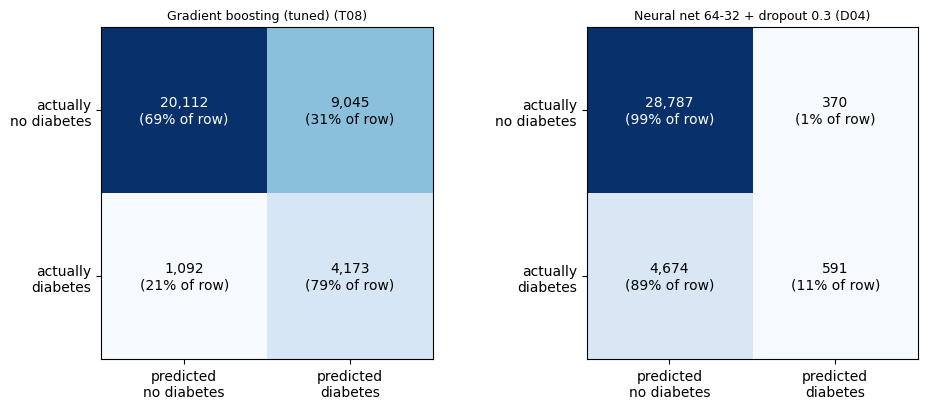

Gradient boosting (tuned) (T08): per 1,000 people, 153 have diabetes. The model finds 121, misses 32 and raises 263 false alarms (68% of the people it flags are false alarms).
Neural net 64-32 + dropout 0.3 (D04): per 1,000 people, 153 have diabetes. The model finds 17, misses 136 and raises 11 false alarms (39% of the people it flags are false alarms).


In [77]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, model_label in zip(axes, (traditional_name, network_name)):
    predicted = (test_scores[model_label] >= 0.5).astype(int)
    confusion = confusion_matrix(y_test_values, predicted)
    ax.imshow(confusion, cmap="Blues"); ax.grid(False)
    for row in range(2):
        for column in range(2):
            ax.text(column, row, f"{confusion[row, column]:,}\n({confusion[row, column] / confusion[row].sum():.0%} of row)",
                    ha="center", va="center", color="white" if confusion[row, column] > confusion.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["predicted\nno diabetes", "predicted\ndiabetes"]); ax.set_yticklabels(["actually\nno diabetes", "actually\ndiabetes"])
    ax.set_title(model_label, fontsize=9)
plt.tight_layout()
save_and_show("err01_confusion_matrices_test")

# The same numbers per 1,000 people, in words
for model_label in (traditional_name, network_name):
    predicted = (test_scores[model_label] >= 0.5).astype(int)
    true_neg, false_pos, false_neg, true_pos = confusion_matrix(y_test_values, predicted).ravel()
    per_1000 = 1000 / len(y_test_values)
    print(f"{model_label}: per 1,000 people, {y_test_values.mean() * 1000:.0f} have diabetes. The model finds {true_pos * per_1000:.0f}, "
          f"misses {false_neg * per_1000:.0f} and raises {false_pos * per_1000:.0f} false alarms "
          f"({false_pos / (false_pos + true_pos):.0%} of the people it flags are false alarms).")

## 5. ROC and precision-recall curves on the test set
- The ROC curve shows the true positive rate (recall) against the false positive rate for every possible cut-off. The area under it (ROC-AUC) is the chance that a randomly chosen person with diabetes gets a higher score than a randomly chosen person without diabetes.
- The precision-recall curve shows precision against recall. When the positive class is rare (here 15%), it tells more than the ROC curve, because the huge number of true negatives makes the ROC curve look good. The dotted line is the precision of a model without any skill (the share of diabetes).
- The round markers show the 0.5 cut-off.

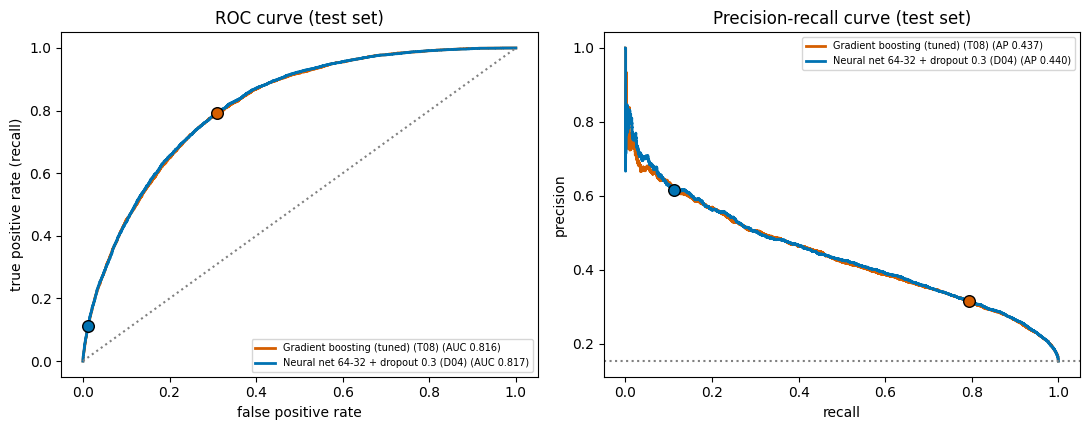

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for model_label, color in [(traditional_name, ORANGE), (network_name, BLUE)]:
    scores = test_scores[model_label]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test_values, scores)
    precision_values, recall_values, _ = precision_recall_curve(y_test_values, scores)
    axes[0].plot(false_positive_rate, true_positive_rate, color=color, lw=2,
                 label=f"{model_label} (AUC {roc_auc_score(y_test_values, scores):.3f})")
    axes[1].plot(recall_values, precision_values, color=color, lw=2,
                 label=f"{model_label} (AP {average_precision_score(y_test_values, scores):.3f})")
    flagged = scores >= 0.5                          # the 0.5 cut-off, drawn as a marker on both curves
    axes[0].scatter(flagged[y_test_values == 0].mean(), flagged[y_test_values == 1].mean(), color=color, s=70, edgecolor="black", zorder=3)
    axes[1].scatter(flagged[y_test_values == 1].mean(), y_test_values[flagged].mean(), color=color, s=70, edgecolor="black", zorder=3)
axes[0].plot([0, 1], [0, 1], ":", color="grey"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate (recall)")
axes[0].set_title("ROC curve (test set)"); axes[0].legend(fontsize=7, loc="lower right")
axes[1].axhline(y_test_values.mean(), color="grey", ls=":"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curve (test set)"); axes[1].legend(fontsize=7)
plt.tight_layout()
save_and_show("err02_roc_pr_test")

## 6. Choosing a cut-off: the trade-off between finding cases and raising false alarms
The cut-off 0.5 is only a convention. Another cut-off moves a model along its precision-recall curve. I choose three cut-offs on the validation set only, and then apply them to the test set:

1. 0.5, the convention.
2. Best F1: the cut-off with the highest F1 on the validation set (a balance between precision and recall).
3. Screening: the highest cut-off that still finds at least 80% of the people with diabetes on the validation set.

This puts the two models at comparable operating points.

In [79]:
def cutoff_for_best_f1(y_true, scores):
    # The cut-off with the highest F1 score.
    precision_values, recall_values, cutoffs = precision_recall_curve(y_true, scores)
    f1_values = 2 * precision_values[:-1] * recall_values[:-1] / np.maximum(precision_values[:-1] + recall_values[:-1], 1e-12)
    return float(cutoffs[np.argmax(f1_values)])


def cutoff_for_recall(y_true, scores, target_recall=0.80):
    # The highest cut-off (fewest false alarms) that still finds at least target_recall of the cases.
    precision_values, recall_values, cutoffs = precision_recall_curve(y_true, scores)
    cutoffs_with_enough_recall = np.where(recall_values[:-1] >= target_recall)[0]
    return float(cutoffs[cutoffs_with_enough_recall.max()])


operating_rows = []
for model_label in (traditional_name, network_name):
    chosen_cutoffs = {"cut-off 0.5": 0.5,
                      "best F1 on validation": cutoff_for_best_f1(y_val.values, validation_scores[model_label]),
                      "recall >= 0.80 on validation": cutoff_for_recall(y_val.values, validation_scores[model_label])}
    for rule, cutoff in chosen_cutoffs.items():
        predicted = (test_scores[model_label] >= cutoff).astype(int)
        true_neg, false_pos, false_neg, true_pos = confusion_matrix(y_test_values, predicted).ravel()
        operating_rows.append({"model": model_label, "cut-off rule": rule, "cut-off": round(cutoff, 3),
                               "people flagged": f"{predicted.mean():.1%}",
                               "recall": round(true_pos / (true_pos + false_neg), 3),
                               "precision": round(true_pos / (true_pos + false_pos), 3),
                               "F1": round(f1_score(y_test_values, predicted), 3),
                               "accuracy": round((true_pos + true_neg) / len(predicted), 3),
                               "false alarms per 1000": round(false_pos * 1000 / len(predicted)),
                               "missed cases per 1000": round(false_neg * 1000 / len(predicted))})
operating_points = pd.DataFrame(operating_rows)
operating_points.to_csv(REPORTS_DIR / "operating_points_test.csv", index=False)
operating_points

,model,cut-off rule,cut-off,people flagged,recall,precision,F1,accuracy,false alarms per 1000,missed cases per 1000
0,Gradient boosting (tuned) (T08),cut-off 0.5,0.500,38.4%,0.793,0.316,0.452,0.706,263,32
1,Gradient boosting (tuned) (T08),best F1 on validation,0.642,24.3%,0.609,0.384,0.471,0.791,149,60
2,Gradient boosting (tuned) (T08),recall >= 0.80 on validation,0.492,39.2%,0.798,0.312,0.448,0.699,270,31
3,Neural net 64-32 + dropout 0.3 (D04),cut-off 0.5,0.500,2.8%,0.112,0.615,0.190,0.853,11,136
4,Neural net 64-32 + dropout 0.3 (D04),best F1 on validation,0.236,25.3%,0.631,0.382,0.476,0.787,156,56
5,Neural net 64-32 + dropout 0.3 (D04),recall >= 0.80 on validation,0.155,38.8%,0.796,0.314,0.451,0.703,266,31


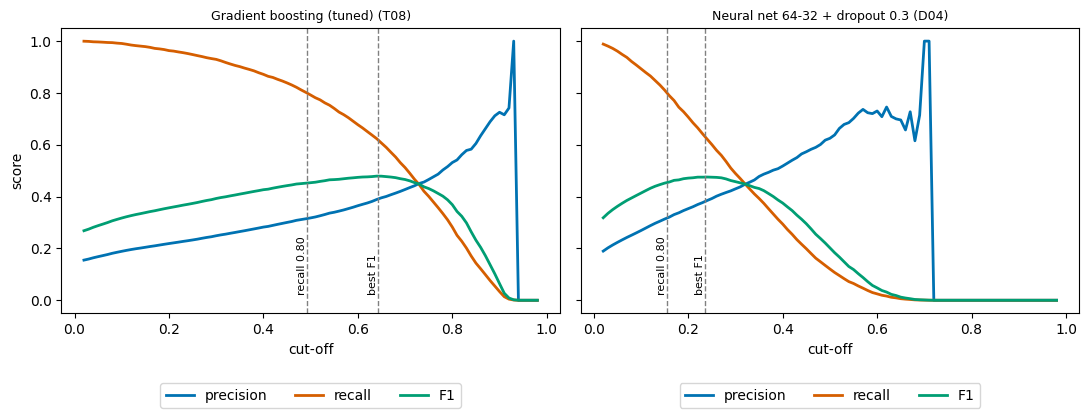

In [80]:
# Precision, recall and F1 against the cut-off (validation set), with the two chosen cut-offs
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, model_label in zip(axes, (traditional_name, network_name)):
    cutoff_grid = np.linspace(0.02, 0.98, 97)
    scores = validation_scores[model_label]
    precision_at_cutoff = [precision_score(y_val.values, scores >= cutoff, zero_division=0) for cutoff in cutoff_grid]
    recall_at_cutoff = [recall_score(y_val.values, scores >= cutoff) for cutoff in cutoff_grid]
    f1_at_cutoff = [f1_score(y_val.values, scores >= cutoff) for cutoff in cutoff_grid]
    ax.plot(cutoff_grid, precision_at_cutoff, color=BLUE, lw=2, label="precision")
    ax.plot(cutoff_grid, recall_at_cutoff, color=ORANGE, lw=2, label="recall")
    ax.plot(cutoff_grid, f1_at_cutoff, color="#009E73", lw=2, label="F1")
    for rule_label, cutoff in [("best F1", cutoff_for_best_f1(y_val.values, scores)), ("recall 0.80", cutoff_for_recall(y_val.values, scores))]:
        ax.axvline(cutoff, color="grey", ls="--", lw=1)
        ax.text(cutoff, 0.02, rule_label, rotation=90, va="bottom", ha="right", fontsize=8)
    ax.set_xlabel("cut-off"); ax.set_title(model_label, fontsize=9)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)      # below the plot, so it hides no curve
axes[0].set_ylabel("score")
plt.tight_layout()
save_and_show("err03_threshold_curves")

## 7. Can the scores be read as probabilities? Calibration
A model is calibrated if, among the people who get a score of about 0.3, about 30% really have diabetes. This matters when the score is shown to a person as a "risk". The plot compares the average score with the real share of diabetes in 10 groups of people sorted by score. A calibrated model lies on the diagonal. The Brier score is the average squared error of the probabilities (lower is better).

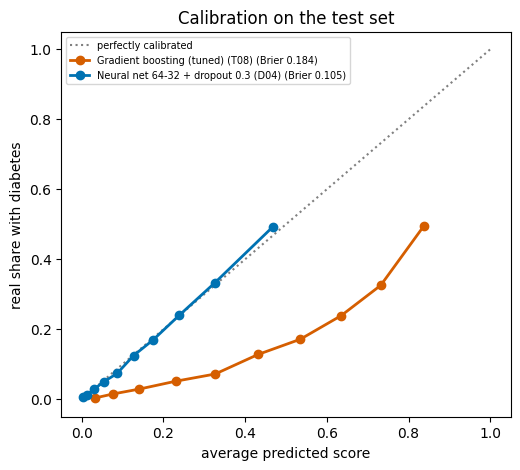

Gradient boosting (tuned) (T08): average score 0.398 against a real diabetes share of 0.153
Neural net 64-32 + dropout 0.3 (D04): average score 0.152 against a real diabetes share of 0.153


In [81]:
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.plot([0, 1], [0, 1], ":", color="grey", label="perfectly calibrated")
for model_label, color in [(traditional_name, ORANGE), (network_name, BLUE)]:
    real_share_with_diabetes, average_score = calibration_curve(y_test_values, test_scores[model_label], n_bins=10, strategy="quantile")
    brier = brier_score_loss(y_test_values, test_scores[model_label])
    ax.plot(average_score, real_share_with_diabetes, marker="o", color=color, lw=2, label=f"{model_label} (Brier {brier:.3f})")
ax.set_xlabel("average predicted score"); ax.set_ylabel("real share with diabetes")
ax.set_title("Calibration on the test set"); ax.legend(fontsize=7)
save_and_show("err04_calibration")
for model_label in (traditional_name, network_name):
    print(f"{model_label}: average score {test_scores[model_label].mean():.3f} against a real diabetes share of {y_test_values.mean():.3f}")

The model trained with class weights (T08) gives scores that are too high on average. The weights make the diabetes class count about 5 times more, so its scores are not probabilities. The network trained without weights (D04) is close to the diagonal. If risk scores were shown to people, the weighted model would first need to be recalibrated, for example on the validation set.

## 8. Bias and variance: is the model too simple or too flexible?
- High bias (underfitting): the model is too simple, so it scores badly on the training data and on new data.
- High variance (overfitting): the model is too flexible, so it scores very well on the training data but clearly worse on new data.

I compare the ROC-AUC on a sample of 30,000 training rows with the ROC-AUC on the validation set. The test set is not used here, so that it stays a clean estimate for the two chosen models.

In [82]:
train_sample_positions = np.random.RandomState(SEED).choice(len(train_scaled), 30000, replace=False)
train_sample_features = train_scaled.iloc[train_sample_positions]
train_sample_labels = y_train.iloc[train_sample_positions].values


def score_with(model, features):
    # Scores of a scikit-learn model or of a Keras network.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    return model.predict(features.values.astype("float32"), batch_size=1024, verbose=0).ravel()


models_to_check = [("Logistic regression (T06)", traditional_results["T06"]["model"]),
                   ("Random forest, unlimited depth (T03)", traditional_results["T03"]["model"]),
                   ("Random forest, tuned (T07)", traditional_results["T07"]["model"]),
                   ("Gradient boosting, tuned (T08)", traditional_results["T08"]["model"]),
                   ("Neural network 128-64-32 (D02)", network_results["D02"]["model"]),
                   ("Neural network + dropout (D04)", network_results["D04"]["model"])]
bias_variance_rows = []
for model_label, model in models_to_check:
    train_auc = roc_auc_score(train_sample_labels, score_with(model, train_sample_features))
    validation_auc = roc_auc_score(y_val.values, score_with(model, val_scaled))
    bias_variance_rows.append({"model": model_label, "train ROC-AUC": round(train_auc, 4),
                               "validation ROC-AUC": round(validation_auc, 4),
                               "gap (train - validation)": round(train_auc - validation_auc, 4)})
bias_variance = pd.DataFrame(bias_variance_rows).set_index("model")
bias_variance

,train ROC-AUC,validation ROC-AUC,gap (train - validation)
model,,,
Logistic regression (T06),0.8047,0.8149,-0.0103
"Random forest, unlimited depth (T03)",0.9998,0.7788,0.2211
"Random forest, tuned (T07)",0.8329,0.8170,0.0159
"Gradient boosting, tuned (T08)",0.8158,0.8199,-0.0042
Neural network 128-64-32 (D02),0.8188,0.8190,-0.0002
Neural network + dropout (D04),0.8142,0.8199,-0.0058


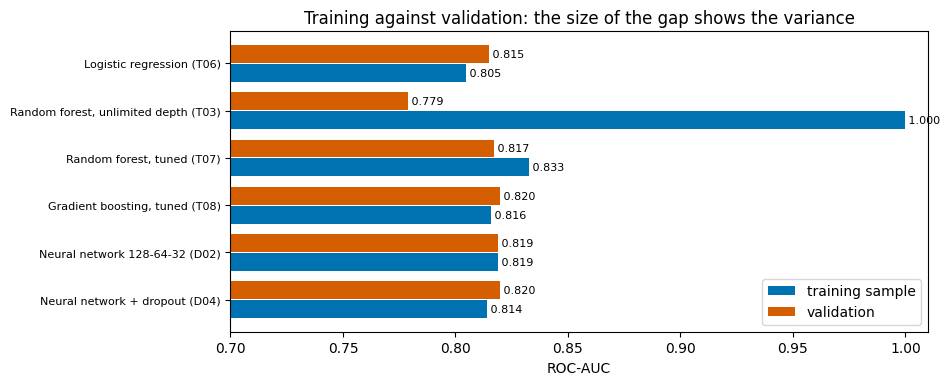

In [83]:
fig, ax = plt.subplots(figsize=(9, 3.9))
bar_positions = np.arange(len(bias_variance))
ax.barh(bar_positions + 0.2, bias_variance["train ROC-AUC"], height=0.38, color=BLUE, label="training sample")
ax.barh(bar_positions - 0.2, bias_variance["validation ROC-AUC"], height=0.38, color=ORANGE, label="validation")
ax.set_yticks(bar_positions); ax.set_yticklabels(bias_variance.index, fontsize=8); ax.invert_yaxis()
ax.set_xlim(0.7, 1.01); ax.set_xlabel("ROC-AUC")
ax.set_title("Training against validation: the size of the gap shows the variance"); ax.legend(loc="lower right")
for position, (train_value, validation_value) in enumerate(zip(bias_variance["train ROC-AUC"], bias_variance["validation ROC-AUC"])):
    ax.text(train_value, position + 0.2, f" {train_value:.3f}", va="center", fontsize=8)
    ax.text(validation_value, position - 0.2, f" {validation_value:.3f}", va="center", fontsize=8)
save_and_show("err05_bias_variance")

The learning curves of the earlier steps are the other half of the evidence: the boosting loss curve (`ml01_boosting_curve.png`), the training-size curve (`ml05_learning_curve_size.png`) and the network curves (`dl_learning_curves_*.png`). Together with the table above, they let me say whether the plateau at a ROC-AUC of 0.82 comes from a model that is too simple, a model that is too flexible, or from a limit in the data.

## 9. Who does the model get wrong? Errors by subgroup
For the selected traditional model at the 0.5 cut-off, I compute the recall (the share of the diabetes cases that are found) and the false positive rate (the share of healthy people who are wrongly flagged) inside groups of people. Large differences between groups mean that the model does not work equally well for everyone. These numbers describe the errors of the model. They do not explain why the errors happen, and some groups are small.

In [84]:
test_answers = X_test.reset_index(drop=True)                     # the answers of the test people, in the same order as the scores
traditional_test_scores = test_scores[traditional_name]

subgroups = {
    "Age group": pd.cut(test_answers["Age"], [0, 4, 8, 11, 13], labels=["18-39", "40-59", "60-74", "75+"]),
    "BMI category": test_answers["bmi_category"].map({0: "underweight", 1: "normal", 2: "overweight", 3: "obese"}),
    "Sex": test_answers["Sex"].map({0.0: "female", 1.0: "male"}),
    "Income": pd.cut(test_answers["Income"], [0, 3, 6, 8], labels=["low (1-3)", "middle (4-6)", "high (7-8)"]),
    "Education": pd.cut(test_answers["Education"], [0, 4, 6], labels=["no college degree", "college graduate"]),
}


def subgroup_table(group_labels, scores, cutoff=0.5):
    # Recall, false positive rate and more, for every group of one variable.
    rows = []
    for group in pd.Series(group_labels).dropna().unique():
        in_group = (group_labels == group).values
        y_group, scores_group = y_test_values[in_group], scores[in_group]
        flagged = scores_group >= cutoff
        rows.append({"group": group, "people": int(in_group.sum()), "diabetes share": round(y_group.mean(), 3),
                     "flagged share": round(flagged.mean(), 3),
                     "recall": round(flagged[y_group == 1].mean(), 3),
                     "false positive rate": round(flagged[y_group == 0].mean(), 3),
                     "precision": round(y_group[flagged].mean(), 3) if flagged.any() else np.nan,
                     "ROC-AUC": round(roc_auc_score(y_group, scores_group), 3) if len(set(y_group)) == 2 else np.nan})
    return pd.DataFrame(rows)


tables_per_variable = []
for variable_name, group_labels in subgroups.items():
    variable_table = subgroup_table(group_labels, traditional_test_scores)
    variable_table.insert(0, "variable", variable_name)
    tables_per_variable.append(variable_table)
subgroup_errors = pd.concat(tables_per_variable, ignore_index=True)
subgroup_errors.to_csv(REPORTS_DIR / "subgroup_errors_test.csv", index=False)
subgroup_errors

,variable,group,people,diabetes share,flagged share,recall,false positive rate,precision,ROC-AUC
0,Age group,75+,4934,0.200,0.589,0.819,0.531,0.279,0.723
1,Age group,40-59,12197,0.126,0.276,0.708,0.214,0.323,0.828
2,Age group,18-39,5122,0.037,0.050,0.378,0.038,0.275,0.855
3,Age group,60-74,12169,0.210,0.550,0.863,0.467,0.330,0.781
4,BMI category,overweight,12394,0.127,0.349,0.735,0.292,0.269,0.791
5,BMI category,obese,12792,0.244,0.602,0.885,0.511,0.359,0.774
6,BMI category,normal,8773,0.061,0.132,0.451,0.112,0.208,0.810
7,BMI category,underweight,463,0.056,0.069,0.231,0.059,0.188,0.802
8,Sex,male,15187,0.166,0.427,0.809,0.351,0.314,0.803
9,Sex,female,19235,0.143,0.350,0.778,0.279,0.318,0.825


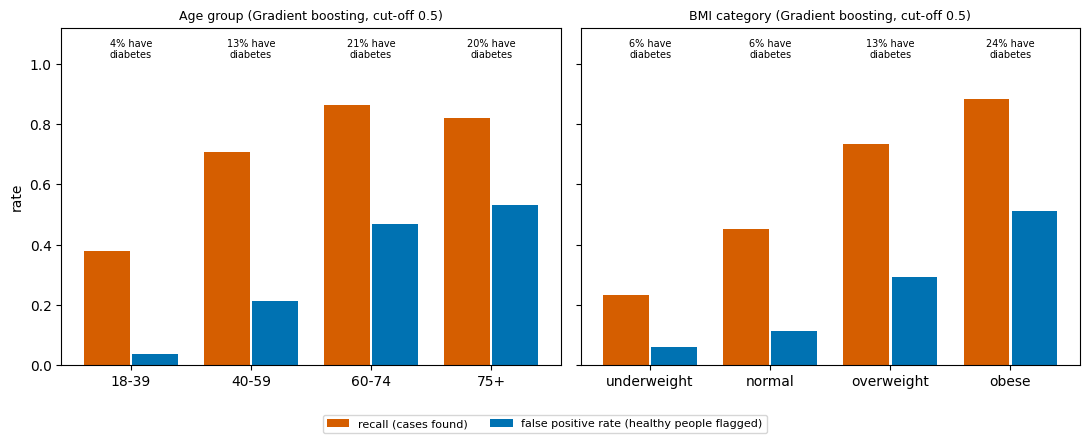

In [85]:
# Recall and false positive rate by age group and by BMI category
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, variable_name, group_order in [(axes[0], "Age group", ["18-39", "40-59", "60-74", "75+"]),
                                       (axes[1], "BMI category", ["underweight", "normal", "overweight", "obese"])]:
    variable_table = subgroup_errors[subgroup_errors["variable"] == variable_name].set_index("group").loc[group_order]
    bar_positions = np.arange(len(group_order))
    ax.bar(bar_positions - 0.2, variable_table["recall"], width=0.38, color=ORANGE, label="recall (cases found)")
    ax.bar(bar_positions + 0.2, variable_table["false positive rate"], width=0.38, color=BLUE, label="false positive rate (healthy people flagged)")
    ax.set_xticks(bar_positions); ax.set_xticklabels(group_order)
    ax.set_title(f"{variable_name} ({traditional_name.split(' (')[0]}, cut-off 0.5)", fontsize=9)
    for position, diabetes_share in enumerate(variable_table["diabetes share"]):
        ax.text(position, 1.02, f"{diabetes_share:.0%} have\ndiabetes", ha="center", fontsize=7)
axes[0].set_ylabel("rate"); axes[0].set_ylim(0, 1.12)
# One legend for both plots, below them, so that it hides no bar. rect leaves room for it at the bottom.
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(legend_handles, legend_labels, loc="lower center", ncol=2, fontsize=8)
plt.tight_layout(rect=[0, 0.07, 1, 1])
save_and_show("err06_subgroup_errors")

## 10. What do the mistakes look like?
I compare the average answers of the four groups of the confusion matrix (traditional model, cut-off 0.5): the cases that were found (true positives), the cases that were missed (false negatives), the false alarms (false positives) and the healthy people who were not flagged (true negatives). If the missed cases look like the healthy people, the model had no information that could tell them apart.

In [86]:
predicted = (traditional_test_scores >= 0.5).astype(int)
mistake_group = np.select([(y_test_values == 1) & (predicted == 1), (y_test_values == 1) & (predicted == 0), (y_test_values == 0) & (predicted == 1)],
                          ["found (TP)", "missed (FN)", "false alarm (FP)"], "healthy, not flagged (TN)")
profile_columns = ["Age", "BMI", "GenHlth", "HighBP", "HighChol", "condition_count", "PhysActivity", "DiffWalk", "Income", "poor_health_days"]
group_profile = test_answers[profile_columns].groupby(mistake_group).mean().T
group_profile = group_profile[["found (TP)", "missed (FN)", "false alarm (FP)", "healthy, not flagged (TN)"]].round(2)
print("Number of people in each group:", pd.Series(mistake_group).value_counts().to_dict())
group_profile

Number of people in each group: {'healthy, not flagged (TN)': 20112, 'false alarm (FP)': 9045, 'found (TP)': 4173, 'missed (FN)': 1092}


,found (TP),missed (FN),false alarm (FP),"healthy, not flagged (TN)"
Age,9.62,8.35,9.71,7.08
BMI,33.17,27.88,31.32,26.63
GenHlth,3.51,2.48,3.24,2.15
HighBP,0.85,0.39,0.79,0.23
HighChol,0.74,0.41,0.67,0.28
condition_count,2.41,0.96,2.11,0.61
PhysActivity,0.60,0.76,0.64,0.80
DiffWalk,0.45,0.08,0.35,0.06
Income,4.96,5.96,5.26,6.33
poor_health_days,14.04,6.37,11.61,5.61


Read each row from left to right. For example, if the missed people have a lower BMI, fewer conditions and a better general health than the people who were found, then they look like the healthy group on exactly the features that the model relies on. This describes an association in this data. It does not describe causes.

## 11. What I would try next
These are ideas to test, not results. None of them has been run. Each one is linked to evidence from the sections above.

| Idea | Evidence that motivates it | What I would measure |
|---|---|---|
| Choose the cut-off for the intended use (screening or confirmation) and report the false alarms and the misses per 1,000 people | Sections 4 and 6: the same ranking quality gives very different balances of errors | Precision and recall at the chosen cut-off on new data |
| Recalibrate the class-weighted model before showing a risk number | Section 7: the weighted scores are too high | The Brier score and the calibration plot after recalibrating on validation data |
| Add information that the survey does not contain (for example blood glucose or HbA1c, waist size, family history) | The plateau near 0.82 across the 21 trained models (Step 6) and the small gaps between training and validation (section 8) suggest that the limit is the information in the 25 features | The ROC-AUC with the extra variables |
| Check the performance for each subgroup before any real use, and collect data from the target population | Section 9: the model does not work equally well for every group, and the data are from US adults in 2015 | The recall and the false positive rate per subgroup on local data |
| Try other model types or more complex networks | Step 6: no model type was clearly better, so I expect small gains at most | A paired comparison on the same splits with repeated runs, as in Step 6 |

## 12. Save the results of this step

In [87]:
saved_files = [file.name for file in sorted(REPORTS_DIR.glob("*")) if file.name in ("test_results.csv", "operating_points_test.csv", "subgroup_errors_test.csv")]
print("Saved:", saved_files)
print("Figures:", sorted(file.name for file in IMAGES_DIR.glob("err0*.png")))
experiment_tracker.logger.info("Step 7 finished: the test set was used for %s and %s only", traditional_name, network_name)

19:06:25 | Step 7 finished: the test set was used for Gradient boosting (tuned) (T08) and Neural net 64-32 + dropout 0.3 (D04) only


Saved: ['operating_points_test.csv', 'subgroup_errors_test.csv', 'test_results.csv']
Figures: ['err01_confusion_matrices_test.png', 'err02_roc_pr_test.png', 'err03_threshold_curves.png', 'err04_calibration.png', 'err05_bias_variance.png', 'err06_subgroup_errors.png']


## 13. Summary of Step 7

What the output above shows (the test set was used only for the two chosen models and the dummy baseline):
- Test results at the 0.5 cut-off. Tuned gradient boosting (T08): ROC-AUC 0.8159, PR-AUC 0.437, recall 0.793, precision 0.316, F1 0.452. Neural network D04: ROC-AUC 0.8172, PR-AUC 0.440, recall 0.112, precision 0.615, F1 0.190. The dummy model reaches an accuracy of 0.847 with a recall of 0.
- Generalisation: from validation to test the ROC-AUC fell by 0.0040 (T08) and by 0.0027 (D04). These are small changes, about the size of the noise from Step 6. Both models were chosen because they had the highest validation score, which tends to make the validation score a little optimistic.
- The two models are practically tied. The paired bootstrap gives a ROC-AUC difference (traditional minus network) of -0.0014 with a 95% interval of [-0.0027, -0.0002]. On these test people the network is slightly better, but the difference is smaller than the split-to-split noise of Step 6 (two standard deviations are 0.0034), and the two had the same ROC-AUC on the validation set (0.8199).
- Mistakes per 1,000 people (15% have diabetes, about 153 people): at the 0.5 cut-off T08 finds 121 cases, misses 32 and raises 263 false alarms (68% of the people it flags are false alarms). D04 finds 17, misses 136 and raises 11 false alarms.
- At matched cut-offs the two models behave the same. With the cut-off chosen on the validation set for a recall of at least 0.80, T08 gets a recall of 0.798 with a precision of 0.312, and D04 gets a recall of 0.796 with a precision of 0.314. With the cut-off for the best F1, the F1 is 0.471 (T08) and 0.476 (D04).
- Calibration: the average score of T08 is 0.398 against a real diabetes share of 0.153 (Brier 0.184), so its scores are not probabilities. The average score of D04 is 0.152 (Brier 0.105) and its curve follows the diagonal.
- Bias and variance: the random forest with unlimited depth fits the training sample almost perfectly (ROC-AUC 0.9998) but scores 0.7788 on validation. That is high variance. The other models have a gap between training and validation between -0.010 and +0.016, and their training ROC-AUC is only 0.80 to 0.83. None of them fits its training data much better than new data, and the more flexible models did not score higher. This fits with a limit in the information in the features (a hypothesis, not a proof).
- Subgroups (T08, cut-off 0.5): the recall is 0.38 for people aged 18-39 but 0.86 for 60-74, and the false positive rate rises from 0.04 to 0.47 and 0.53 for the two oldest groups. Inside a group, the ROC-AUC falls from 0.855 (18-39) to 0.723 (75+). By income, the false positive rate is 0.50 for the low group and 0.22 for the high group, while the diabetes share is 24% and 11%.
- The people who are missed look healthy. The missed cases have on average 0.96 conditions, a BMI of 27.9 and a general health score of 2.48. That is closer to the healthy people who were not flagged (0.61, 26.6 and 2.15) than to the cases that were found (2.41, 33.2 and 3.51). The false alarms look like the cases that were found.

Questions I answer in my own words before the report:
1. What does a missed case cost, compared with a false alarm, in a screening setting? Which cut-off would I use, and why?
2. Using the bias-variance table and the learning curves, why does the ROC-AUC stop at about 0.82? Is the model too simple, too flexible, or is the limit in the data? Which numbers support my answer?
3. What fairness and safety concerns do the subgroup results raise for using this model in practice, and what would I check first?